# Result 8：LC5 肺癌样本 Multi_Axis_Lactate_Glutamine_LPA 三轴混合生态位分析

**目的：**验证 TuMeNiche 在 LC5 肺癌样本中识别到的 `Multi_Axis_Lactate_Glutamine_LPA` 是否具有病理/医学相关性。  

本 notebook 按照以下证据链组织：

1. **空间定位主图**：左侧显示病理 Tumor / Non-Tumor 注释，右侧只高亮 `Multi_Axis_Lactate_Glutamine_LPA`，其他 spot 统一灰色。
2. **病理区域富集**：检验三轴混合生态位是否富集于病理肿瘤区域。
3. **肿瘤边界/侵袭前沿分析**：检验三轴生态位是否更接近 tumor-normal interface。
4. **三轴共激活验证**：优先使用 `Coupling_Lactate / Coupling_Glutamine / Coupling_LPA`；若最终文件中没有这些列，则使用基因集 score 兜底。
5. **SpaCET 细胞组成解释**：分析三轴生态位中 Malignant、CAF、Macrophage、T cell 等细胞组成。
6. **DEG + ORA/GSEA**：使用原始 LC5.h5ad 的 17845 genes 做 `Target_Niche vs Other_Tumor_Regions`。
7. **Permutation 对照**：验证三轴生态位与病理肿瘤区重叠、空间聚集是否强于随机。

> 注意：本 notebook 的空间图画法沿用原 LC5 识别 notebook 的 Squidpy 写法：不直接传入 `palette=dict`，而是把颜色写入 `adata.uns["xxx_colors"]`。

In [2]:
# =========================================================
# Cell 1: 全局配置与依赖导入
# =========================================================
import os
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

from scipy import sparse
from scipy.stats import fisher_exact, chi2_contingency, mannwhitneyu, hypergeom
from statsmodels.stats.multitest import multipletests
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")

# 如果 seaborn 可用，用于部分统计图；不可用时不影响主图绘制
try:
    import seaborn as sns
    HAS_SEABORN = True
except Exception:
    HAS_SEABORN = False

# -----------------------------
# 1. 路径配置
# -----------------------------
SAMPLE_NAME = "LC5"
TARGET_NICHE = "Multi_Axis_Lactate_Glutamine_LPA"

# 原始 17845 genes 表达矩阵：用于 DEG / GSEA / score
ORIGINAL_H5AD = "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/lung_cancer_and_kidney_cancer/LC5.h5ad"

# TuMeNiche 最终识别结果：用于 Level2_Micro_Niche / Pathology_Binary_ARI / spatial metadata
FINAL_H5AD = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/lung_cancer_and_kidney_cancer/LC5/SpaCET_And_My/lung_cancer_and_kidney_cancer_LC5_NicheCompassAndmy_Final.h5ad"

# Result 8 输出目录
SAVE_DIR = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA"
Path(SAVE_DIR).mkdir(parents=True, exist_ok=True)

# 本地 GMT 路径
GMT_DIR = "/home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB"

# permutation 次数：正式结果建议 500 或 1000
N_PERM = 500
RANDOM_SEED = 42

# 空间 KNN 参数
KNN_K = 8

# DEG 阈值，仅用于筛选上调基因做 ORA；完整 DEG 表不按阈值截断
DEG_PADJ_CUTOFF = 0.05
DEG_LOGFC_CUTOFF = 0.25

# 是否强制认为原始 LC5.h5ad 是 counts 并做 normalize_total + log1p
# 对 DEG / score 建议设为 True
ASSUME_RAW_COUNTS = True

np.random.seed(RANDOM_SEED)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("✅ 全局配置完成")
print("SAMPLE_NAME:", SAMPLE_NAME)
print("TARGET_NICHE:", TARGET_NICHE)
print("SAVE_DIR:", SAVE_DIR)

✅ 全局配置完成
SAMPLE_NAME: LC5
TARGET_NICHE: Multi_Axis_Lactate_Glutamine_LPA
SAVE_DIR: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA


In [3]:
# =========================================================
# Cell 2: 读取原始 LC5 表达矩阵 + 最终 TuMeNiche 标签并对齐
# =========================================================
print("=== 读取数据 ===")
print("原始表达矩阵:", ORIGINAL_H5AD)
print("最终 TuMeNiche 结果:", FINAL_H5AD)

adata_raw = sc.read_h5ad(ORIGINAL_H5AD)
adata_final = sc.read_h5ad(FINAL_H5AD)

# 防止 obs index 类型不一致
adata_raw.obs_names = adata_raw.obs_names.astype(str)
adata_final.obs_names = adata_final.obs_names.astype(str)

common_obs = adata_raw.obs_names.intersection(adata_final.obs_names)
if len(common_obs) == 0:
    raise ValueError("❌ 原始 h5ad 与最终 h5ad 没有共同 obs_names，无法合并标签。")

if len(common_obs) < adata_raw.n_obs:
    print(f"⚠️ 原始 h5ad 中有 {adata_raw.n_obs - len(common_obs)} 个 spots 未在最终结果中找到，将仅保留共同 spots。")
if len(common_obs) < adata_final.n_obs:
    print(f"⚠️ 最终 h5ad 中有 {adata_final.n_obs - len(common_obs)} 个 spots 未在原始表达矩阵中找到，将仅保留共同 spots。")

adata = adata_raw[common_obs].copy()
adata_final = adata_final[common_obs].copy()

# 保证 gene names 唯一
adata.var_names_make_unique()

# 如果原始 adata 缺少空间信息，则从最终 adata 补齐
if "spatial" not in adata.obsm.keys() and "spatial" in adata_final.obsm.keys():
    adata.obsm["spatial"] = adata_final.obsm["spatial"].copy()

if "spatial" not in adata.uns.keys() and "spatial" in adata_final.uns.keys():
    adata.uns["spatial"] = adata_final.uns["spatial"].copy()

# 合并最终结果中的关键 obs 列
key_cols = [
    "ground_truth",
    "Pathology_Binary_ARI",
    "Level1_Macro_Region",
    "Level2_Micro_Niche",
    "Final_Niche_Type",
]

# 同时保留 Coupling / Active 列，如果最终文件中仍存在这些列则优先用于三轴共激活验证
extra_cols = [
    c for c in adata_final.obs.columns
    if c.startswith("Coupling_") or c.startswith("Active_") or c.startswith("Score_")
]

merge_cols = [c for c in key_cols + extra_cols if c in adata_final.obs.columns]
for col in merge_cols:
    adata.obs[col] = adata_final.obs[col].values

# 如果最终 h5ad 中没有 Pathology_Binary_ARI，则按照原 LC5 notebook 的 ground_truth 规则重新生成
if "Pathology_Binary_ARI" not in adata.obs.columns:
    if "ground_truth" not in adata.obs.columns:
        raise KeyError("❌ 缺少 ground_truth，无法生成 Pathology_Binary_ARI。")
    gt_map_int = {
        "TUM": 1,
        "NOR": 0,
        "TLS": 0,
        "INFL": 0,
    }
    gt_map_str = {
        1: "Pathology_Tumor",
        0: "Pathology_Non_Tumor",
    }
    patho_clean = adata.obs["ground_truth"].astype(str).str.strip()
    pathology_numeric = patho_clean.map(gt_map_int)
    adata.obs["Pathology_Binary_ARI"] = pathology_numeric.map(gt_map_str).fillna("Unmapped_for_ARI")

if "Level2_Micro_Niche" not in adata.obs.columns:
    raise KeyError("❌ 最终 h5ad 中缺少 Level2_Micro_Niche，无法进行 Result 8 分析。")

# 类型规范化
adata.obs["Level2_Micro_Niche"] = adata.obs["Level2_Micro_Niche"].astype(str)
adata.obs["Pathology_Binary_ARI"] = adata.obs["Pathology_Binary_ARI"].astype(str)

if "Level1_Macro_Region" in adata.obs.columns:
    adata.obs["Level1_Macro_Region"] = adata.obs["Level1_Macro_Region"].astype(str)
else:
    # 如果没有 Level1，则用病理 Tumor/Non-Tumor 兜底
    adata.obs["Level1_Macro_Region"] = np.where(
        adata.obs["Pathology_Binary_ARI"].astype(str) == "Pathology_Tumor",
        "Tumor_Region",
        "Healthy_Region",
    )

# 目标生态位标记
adata.obs["Is_Target_Niche"] = adata.obs["Level2_Micro_Niche"].astype(str) == TARGET_NICHE

# 肿瘤内部比较分组：Target_Niche vs Other_Tumor_Regions
# 优先使用 Level1_Macro_Region；如果目标生态位没有被 Level1 标成 Tumor，也仍然强制归入 Target_Niche。
is_level1_tumor = adata.obs["Level1_Macro_Region"].astype(str) == "Tumor_Region"
is_target = adata.obs["Is_Target_Niche"].values

adata.obs["Result8_Group"] = "Healthy_or_NonTarget_Region"
adata.obs.loc[is_level1_tumor & (~is_target), "Result8_Group"] = "Other_Tumor_Regions"
adata.obs.loc[is_target, "Result8_Group"] = "Target_Niche"
adata.obs.loc[(~is_level1_tumor) & (~is_target), "Result8_Group"] = "Healthy_Region"

result8_order = ["Target_Niche", "Other_Tumor_Regions", "Healthy_Region"]
adata.obs["Result8_Group"] = pd.Categorical(
    adata.obs["Result8_Group"].astype(str),
    categories=result8_order,
    ordered=True,
)

print("✅ 数据合并完成")
print(adata)
print("\nLevel2_Micro_Niche 统计：")
print(adata.obs["Level2_Micro_Niche"].value_counts())
print("\nPathology_Binary_ARI 统计：")
print(adata.obs["Pathology_Binary_ARI"].value_counts())
print("\nResult8_Group 统计：")
print(adata.obs["Result8_Group"].value_counts())

if adata.obs["Is_Target_Niche"].sum() == 0:
    raise ValueError(f"❌ 没有找到目标生态位：{TARGET_NICHE}")

=== 读取数据 ===
原始表达矩阵: /home/zhangjunyi/xiangmu/nichecompass-main/datasets/lung_cancer_and_kidney_cancer/LC5.h5ad
最终 TuMeNiche 结果: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/lung_cancer_and_kidney_cancer/LC5/SpaCET_And_My/lung_cancer_and_kidney_cancer_LC5_NicheCompassAndmy_Final.h5ad


✅ 数据合并完成
AnnData object with n_obs × n_vars = 622 × 17845
    obs: 'in_tissue', 'x_array', 'y_array', 'x_pixel', 'y_pixel', 'manual_anno', 'manual_anno_tls', 'aestetik_manual_anno', 'aestetik_manual_anno_tls', 'ground_truth', 'blur_score', 'Ground_Truth_Binary', 'Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Mast', 'Neutrophil', 'Unidentifiable', 'B cell naive', 'B cell non-switched memory', 'B cell switched memory', 'B cell exhausted', 'T CD4 naive', 'Th1', 'Th2', 'Th17', 'Tfh', 'Treg', 'T CD8 naive', 'T CD8 central memory', 'T CD8 effector memory', 'T CD8 effector', 'T CD8 exhausted', 'cDC1 CLEC9A', 'cDC2 CD1C', 'cDC3 LAMP3', 'Macrophage M1', 'Macrophage M2', 'Macrophage other', 'Pathology_Binary_ARI', 'Level1_Macro_Region', 'Level2_Micro_Niche', 'Is_Target_Niche', 'Result8_Group'
    var: 'gene_ids', 'feature_types', 'gene_name'
    uns: 'Ground_Truth_Binary_colors', 'remove_UNASSIGNED_info', 'spatial'
    obsm: 'spatial'


In [4]:
# =========================================================
# Cell 3: 输入信息检查与保存
# =========================================================
summary_rows = []
summary_rows.append({"item": "sample", "value": SAMPLE_NAME})
summary_rows.append({"item": "n_spots", "value": int(adata.n_obs)})
summary_rows.append({"item": "n_genes_raw", "value": int(adata.n_vars)})
summary_rows.append({"item": "target_niche", "value": TARGET_NICHE})
summary_rows.append({"item": "target_niche_spots", "value": int(adata.obs["Is_Target_Niche"].sum())})
summary_rows.append({"item": "has_spatial_obsm", "value": "spatial" in adata.obsm.keys()})
summary_rows.append({"item": "has_spatial_uns", "value": "spatial" in adata.uns.keys()})
summary_rows.append({"item": "coupling_cols", "value": ";".join([c for c in adata.obs.columns if c.startswith("Coupling_")])})
summary_rows.append({"item": "active_cols", "value": ";".join([c for c in adata.obs.columns if c.startswith("Active_")])})

input_summary_df = pd.DataFrame(summary_rows)
input_summary_path = os.path.join(SAVE_DIR, "Result8_Input_Check_Summary.csv")
input_summary_df.to_csv(input_summary_path, index=False, encoding="utf-8-sig")

print("✅ 输入检查表已保存：", input_summary_path)
display(input_summary_df)

✅ 输入检查表已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_Input_Check_Summary.csv


,item,value
0,sample,LC5
1,n_spots,622
2,n_genes_raw,17845
3,target_niche,Multi_Axis_Lactate_Glutamine_LPA
4,target_niche_spots,67
5,has_spatial_obsm,True
6,has_spatial_uns,True
7,coupling_cols,
8,active_cols,


## Figure 8A：空间定位主图

按照你的要求，这里只画一个两联图：

- **左图**：LC5 肺癌切片的病理 Tumor / Non-Tumor 注释区域；
- **右图**：整个切片中只高亮 `Multi_Axis_Lactate_Glutamine_LPA`，其他 spots 统一为灰色。

这里严格沿用原 LC5 notebook 的 Squidpy 可视化方式：**不传 `palette=dict`，而是写入 `adata.uns["xxx_colors"]`。**

当前使用 library_id: library_id


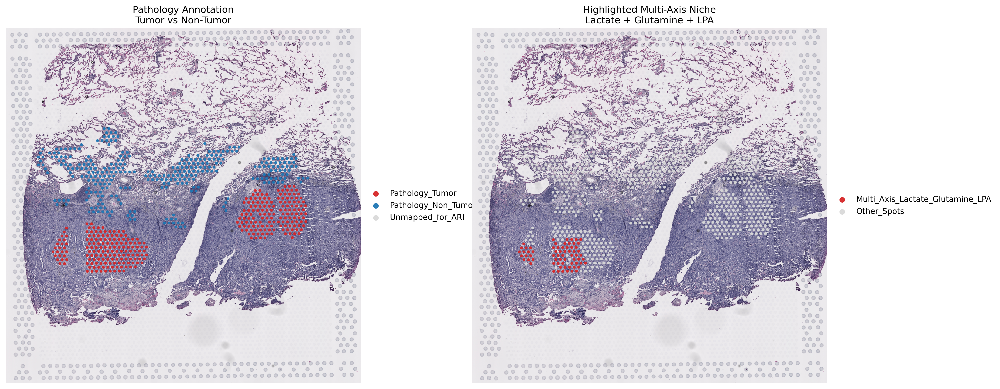

✅ Figure 8A 已保存：
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8A_Pathology_vs_Multi_Axis_Lactate_Glutamine_LPA_Highlight.png
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8A_Pathology_vs_Multi_Axis_Lactate_Glutamine_LPA_Highlight.pdf


In [5]:
# =========================================================
# Cell 4: Figure 8A - 病理 Tumor/Non-Tumor vs 三轴混合生态位高亮图
# =========================================================
import squidpy as sq

if "spatial" not in adata.uns.keys() or "spatial" not in adata.obsm.keys():
    raise KeyError("❌ adata 中缺少 spatial 信息，无法绘制 H&E 空间图。")

library_id = list(adata.uns["spatial"].keys())[0]
print("当前使用 library_id:", library_id)

# --------------------------------------------------
# 1. 病理二分类配色：沿用原 LC5 notebook 逻辑
# --------------------------------------------------
pathology_palette = {
    "Pathology_Tumor": "#d62728",
    "Pathology_Non_Tumor": "#1f77b4",
    "Unmapped_for_ARI": "#d9d9d9",
}
pathology_categories = ["Pathology_Tumor", "Pathology_Non_Tumor", "Unmapped_for_ARI"]

adata.obs["Pathology_Binary_ARI"] = pd.Categorical(
    adata.obs["Pathology_Binary_ARI"].astype(str),
    categories=pathology_categories,
    ordered=False,
)
adata.uns["Pathology_Binary_ARI_colors"] = [pathology_palette[x] for x in pathology_categories]

# --------------------------------------------------
# 2. 只高亮目标三轴生态位：其他 spot 统一灰色
# --------------------------------------------------
highlight_col = "Highlight_Multi_Axis_Lactate_Glutamine_LPA"
adata.obs[highlight_col] = np.where(
    adata.obs["Level2_Micro_Niche"].astype(str) == TARGET_NICHE,
    TARGET_NICHE,
    "Other_Spots",
)

highlight_categories = [TARGET_NICHE, "Other_Spots"]
adata.obs[highlight_col] = pd.Categorical(
    adata.obs[highlight_col].astype(str),
    categories=highlight_categories,
    ordered=True,
)

# 目标生态位使用醒目红色，其他 spot 使用浅灰色
highlight_palette = {
    TARGET_NICHE: "#d62728",
    "Other_Spots": "#d9d9d9",
}
adata.uns[f"{highlight_col}_colors"] = [highlight_palette[x] for x in highlight_categories]

# --------------------------------------------------
# 3. 绘图：不要传 palette=dict，使用 adata.uns[xxx_colors]
# --------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(18, 7), dpi=300)

sq.pl.spatial_scatter(
    adata,
    library_id=library_id,
    img=True,
    color="Pathology_Binary_ARI",
    size=10,
    alpha=0.95,
    title="Pathology Annotation\nTumor vs Non-Tumor",
    frameon=False,
    legend_loc="right margin",
    ax=axs[0],
)

sq.pl.spatial_scatter(
    adata,
    library_id=library_id,
    img=True,
    color=highlight_col,
    size=10,
    alpha=0.95,
    title="Highlighted Multi-Axis Niche\nLactate + Glutamine + LPA",
    frameon=False,
    legend_loc="right margin",
    ax=axs[1],
)

plt.tight_layout()

fig8a_png = os.path.join(SAVE_DIR, "Fig8A_Pathology_vs_Multi_Axis_Lactate_Glutamine_LPA_Highlight.png")
fig8a_pdf = os.path.join(SAVE_DIR, "Fig8A_Pathology_vs_Multi_Axis_Lactate_Glutamine_LPA_Highlight.pdf")
plt.savefig(fig8a_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
plt.savefig(fig8a_pdf, dpi=300, bbox_inches="tight", pad_inches=0.1)
plt.show()

print("✅ Figure 8A 已保存：")
print(fig8a_png)
print(fig8a_pdf)

当前使用 library_id: library_id


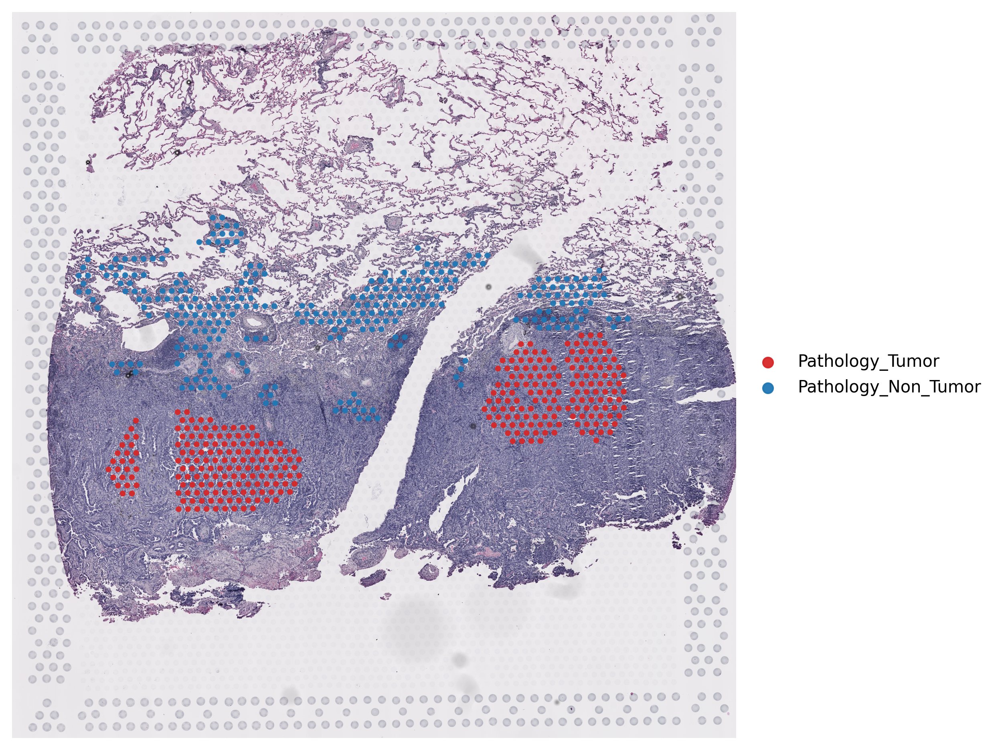

✅ Pathology 图已保存
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8A1_Pathology_Tumor_vs_NonTumor.png
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8A1_Pathology_Tumor_vs_NonTumor.pdf


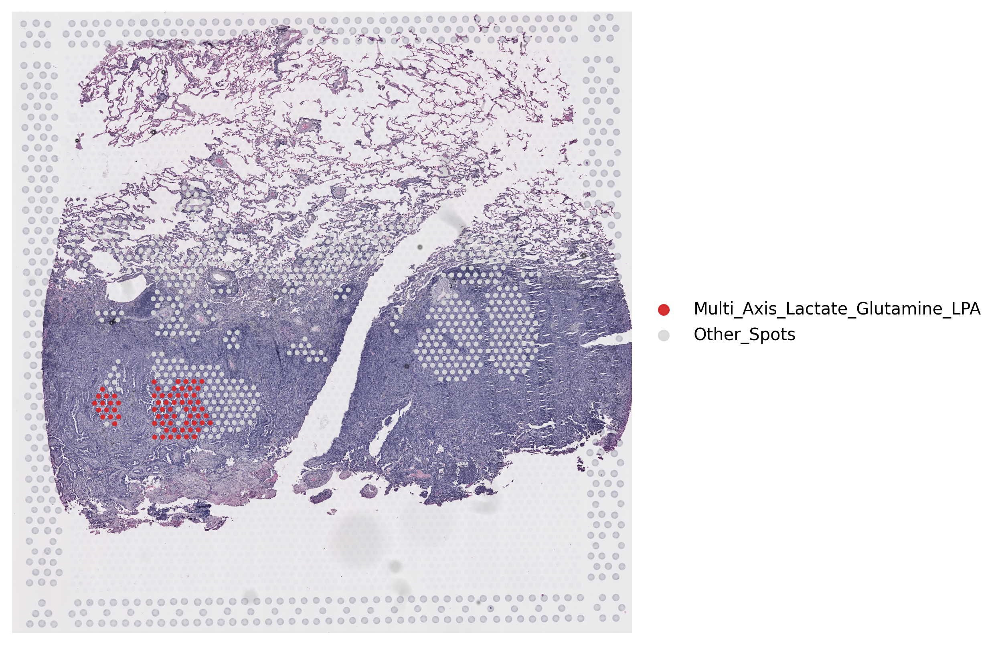

✅ Multi-Axis 图已保存
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8A2_Multi_Axis_Lactate_Glutamine_LPA_Highlight.png
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8A2_Multi_Axis_Lactate_Glutamine_LPA_Highlight.pdf


In [6]:
# =========================================================
# Cell 4: Figure 8A
# Pathology Tumor/Non-Tumor
# vs
# Multi-Axis Niche Highlight
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import squidpy as sq

# --------------------------------------------------
# 检查空间信息
# --------------------------------------------------
if "spatial" not in adata.uns.keys() or "spatial" not in adata.obsm.keys():
    raise KeyError("❌ adata 中缺少 spatial 信息，无法绘制 H&E 空间图。")

library_id = list(adata.uns["spatial"].keys())[0]
print("当前使用 library_id:", library_id)

# ==================================================
# 1. Pathology 图
# 去除 Unmapped_for_ARI
# ==================================================

valid_mask = adata.obs["Pathology_Binary_ARI"].isin(
    [
        "Pathology_Tumor",
        "Pathology_Non_Tumor"
    ]
)

adata_pathology = adata[valid_mask].copy()

pathology_palette = {
    "Pathology_Tumor": "#d62728",
    "Pathology_Non_Tumor": "#1f77b4",
}

pathology_categories = [
    "Pathology_Tumor",
    "Pathology_Non_Tumor",
]

adata_pathology.obs["Pathology_Binary_ARI"] = pd.Categorical(
    adata_pathology.obs["Pathology_Binary_ARI"].astype(str),
    categories=pathology_categories,
)

adata_pathology.uns["Pathology_Binary_ARI_colors"] = [
    pathology_palette[x]
    for x in pathology_categories
]

# ==================================================
# 2. 三轴生态位高亮
# ==================================================

highlight_col = "Highlight_Multi_Axis_Lactate_Glutamine_LPA"

adata.obs[highlight_col] = np.where(
    adata.obs["Level2_Micro_Niche"].astype(str) == TARGET_NICHE,
    TARGET_NICHE,
    "Other_Spots",
)

highlight_categories = [
    TARGET_NICHE,
    "Other_Spots",
]

adata.obs[highlight_col] = pd.Categorical(
    adata.obs[highlight_col],
    categories=highlight_categories,
    ordered=True,
)

highlight_palette = {
    TARGET_NICHE: "#d62728",
    "Other_Spots": "#d9d9d9",
}

adata.uns[f"{highlight_col}_colors"] = [
    highlight_palette[x]
    for x in highlight_categories
]

# ==================================================
# Figure 8A-1
# Pathology Annotation
# ==================================================

fig, ax = plt.subplots(
    figsize=(8, 7),
    dpi=300
)

sq.pl.spatial_scatter(
    adata_pathology,
    library_id=library_id,
    img=True,
    color="Pathology_Binary_ARI",
    size=10,
    alpha=0.95,
    frameon=False,
    legend_loc="right margin",
    ax=ax,
)

# 去除标题
ax.set_title("")

# 去除坐标轴
ax.axis("off")

plt.tight_layout()

pathology_png = os.path.join(
    SAVE_DIR,
    "Fig8A1_Pathology_Tumor_vs_NonTumor.png"
)

pathology_pdf = os.path.join(
    SAVE_DIR,
    "Fig8A1_Pathology_Tumor_vs_NonTumor.pdf"
)

plt.savefig(
    pathology_png,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0,
)

plt.savefig(
    pathology_pdf,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0,
)

plt.show()

print("✅ Pathology 图已保存")
print(pathology_png)
print(pathology_pdf)

# ==================================================
# Figure 8A-2
# Multi-Axis Highlight
# ==================================================

fig, ax = plt.subplots(
    figsize=(8, 7),
    dpi=300
)

sq.pl.spatial_scatter(
    adata,
    library_id=library_id,
    img=True,
    color=highlight_col,
    size=10,
    alpha=0.95,
    frameon=False,
    legend_loc="right margin",
    ax=ax,
)

# 去除标题
ax.set_title("")

# 去除坐标轴
ax.axis("off")

plt.tight_layout()

niche_png = os.path.join(
    SAVE_DIR,
    "Fig8A2_Multi_Axis_Lactate_Glutamine_LPA_Highlight.png"
)

niche_pdf = os.path.join(
    SAVE_DIR,
    "Fig8A2_Multi_Axis_Lactate_Glutamine_LPA_Highlight.pdf"
)

plt.savefig(
    niche_png,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0,
)

plt.savefig(
    niche_pdf,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0,
)

plt.show()

print("✅ Multi-Axis 图已保存")
print(niche_png)
print(niche_pdf)

## 病理肿瘤区域富集分析

该部分回答：`Multi_Axis_Lactate_Glutamine_LPA` 是否显著富集在病理 Tumor 区域，而不是随机落在 Tumor / Non-Tumor 区域中。

2×2 contingency table:


,Pathology_Tumor,Pathology_Non_Tumor
Multi_Axis_Lactate_Glutamine_LPA,67,0
Other_Spots,245,310



Overlap summary:


,metric,value
0,target_total_spots,6.700000e+01
1,target_spots_in_Pathology_Tumor,6.700000e+01
2,target_spots_in_Pathology_Non_Tumor,0.000000e+00
3,target_tumor_overlap_ratio,1.000000e+00
4,target_ratio_within_Pathology_Tumor,2.147436e-01
5,target_ratio_within_Pathology_Non_Tumor,0.000000e+00
6,fisher_exact_odds_ratio,inf
7,fisher_exact_pvalue,2.580561e-22
8,chi_square_pvalue,1.766582e-17


✅ 保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_TargetNiche_Pathology_Overlap_Stats.csv


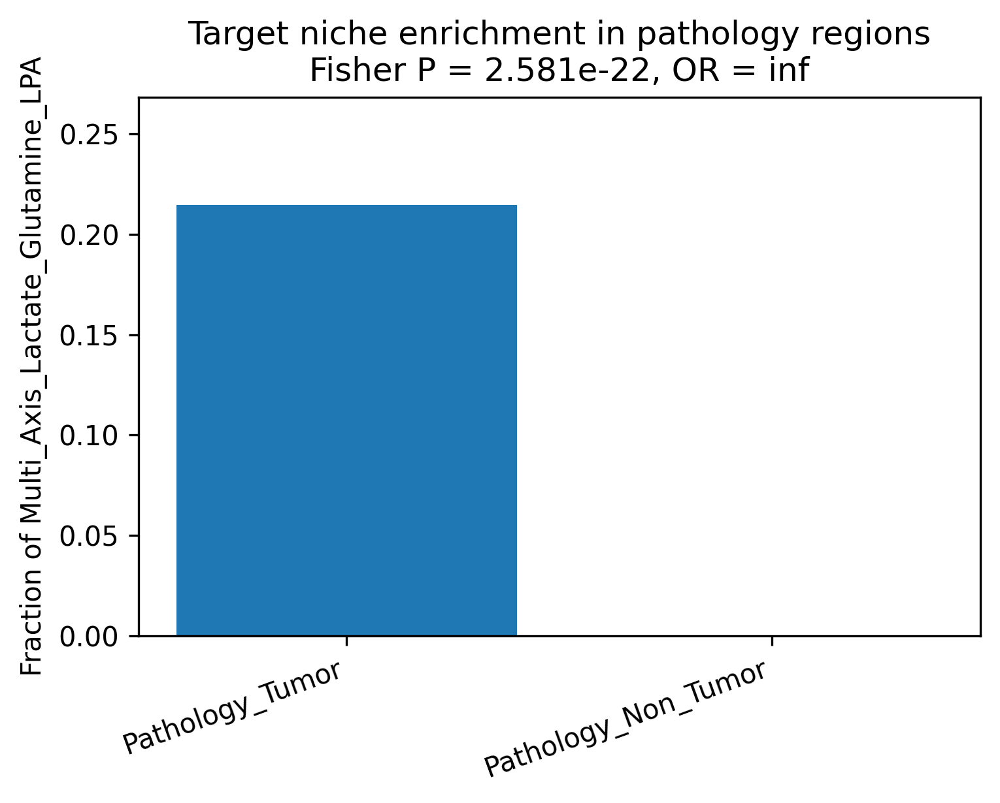

✅ 富集比例图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8B_TargetNiche_Fraction_in_Pathology_Regions.png


In [7]:
# =========================================================
# Cell 5: 三轴混合生态位与病理 Tumor 区域重叠 / 富集分析
# =========================================================
valid_pathology_mask = adata.obs["Pathology_Binary_ARI"].astype(str).isin([
    "Pathology_Tumor",
    "Pathology_Non_Tumor",
])

df_overlap = adata.obs.loc[valid_pathology_mask, ["Pathology_Binary_ARI", "Is_Target_Niche"]].copy()
df_overlap["Is_Target_Niche"] = df_overlap["Is_Target_Niche"].astype(bool)

# 构建 2×2 表：行=target/non-target，列=tumor/non-tumor
n_target_tumor = int(((df_overlap["Is_Target_Niche"]) & (df_overlap["Pathology_Binary_ARI"].astype(str) == "Pathology_Tumor")).sum())
n_target_nontumor = int(((df_overlap["Is_Target_Niche"]) & (df_overlap["Pathology_Binary_ARI"].astype(str) == "Pathology_Non_Tumor")).sum())
n_other_tumor = int(((~df_overlap["Is_Target_Niche"]) & (df_overlap["Pathology_Binary_ARI"].astype(str) == "Pathology_Tumor")).sum())
n_other_nontumor = int(((~df_overlap["Is_Target_Niche"]) & (df_overlap["Pathology_Binary_ARI"].astype(str) == "Pathology_Non_Tumor")).sum())

contingency = np.array([
    [n_target_tumor, n_target_nontumor],
    [n_other_tumor, n_other_nontumor],
])

odds_ratio, fisher_p = fisher_exact(contingency)
try:
    chi2, chi2_p, _, _ = chi2_contingency(contingency)
except Exception:
    chi2, chi2_p = np.nan, np.nan

target_total = n_target_tumor + n_target_nontumor
pathology_tumor_total = n_target_tumor + n_other_tumor
pathology_nontumor_total = n_target_nontumor + n_other_nontumor

overlap_summary = pd.DataFrame([
    {"metric": "target_total_spots", "value": target_total},
    {"metric": "target_spots_in_Pathology_Tumor", "value": n_target_tumor},
    {"metric": "target_spots_in_Pathology_Non_Tumor", "value": n_target_nontumor},
    {"metric": "target_tumor_overlap_ratio", "value": n_target_tumor / target_total if target_total > 0 else np.nan},
    {"metric": "target_ratio_within_Pathology_Tumor", "value": n_target_tumor / pathology_tumor_total if pathology_tumor_total > 0 else np.nan},
    {"metric": "target_ratio_within_Pathology_Non_Tumor", "value": n_target_nontumor / pathology_nontumor_total if pathology_nontumor_total > 0 else np.nan},
    {"metric": "fisher_exact_odds_ratio", "value": odds_ratio},
    {"metric": "fisher_exact_pvalue", "value": fisher_p},
    {"metric": "chi_square_pvalue", "value": chi2_p},
])

overlap_csv = os.path.join(SAVE_DIR, "Result8_TargetNiche_Pathology_Overlap_Stats.csv")
overlap_summary.to_csv(overlap_csv, index=False, encoding="utf-8-sig")

contingency_df = pd.DataFrame(
    contingency,
    index=[TARGET_NICHE, "Other_Spots"],
    columns=["Pathology_Tumor", "Pathology_Non_Tumor"],
)
contingency_csv = os.path.join(SAVE_DIR, "Result8_TargetNiche_Pathology_Contingency.csv")
contingency_df.to_csv(contingency_csv, encoding="utf-8-sig")

print("2×2 contingency table:")
display(contingency_df)
print("\nOverlap summary:")
display(overlap_summary)
print("✅ 保存：", overlap_csv)

# 可视化：Tumor / Non-Tumor 中目标生态位比例
bar_df = pd.DataFrame([
    {
        "Pathology_Region": "Pathology_Tumor",
        "Target_Niche_Ratio": n_target_tumor / pathology_tumor_total if pathology_tumor_total > 0 else np.nan,
        "Target_Niche_Count": n_target_tumor,
        "Total_Spots": pathology_tumor_total,
    },
    {
        "Pathology_Region": "Pathology_Non_Tumor",
        "Target_Niche_Ratio": n_target_nontumor / pathology_nontumor_total if pathology_nontumor_total > 0 else np.nan,
        "Target_Niche_Count": n_target_nontumor,
        "Total_Spots": pathology_nontumor_total,
    },
])

fig, ax = plt.subplots(figsize=(5.2, 4.2), dpi=300)
ax.bar(bar_df["Pathology_Region"], bar_df["Target_Niche_Ratio"])
ax.set_ylabel(f"Fraction of {TARGET_NICHE}")
ax.set_xlabel("")
ax.set_title(f"Target niche enrichment in pathology regions\nFisher P = {fisher_p:.3e}, OR = {odds_ratio:.3f}")
ax.set_ylim(0, min(1, max(0.05, np.nanmax(bar_df["Target_Niche_Ratio"]) * 1.25)))
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

overlap_bar_png = os.path.join(SAVE_DIR, "Fig8B_TargetNiche_Fraction_in_Pathology_Regions.png")
plt.savefig(overlap_bar_png, dpi=300, bbox_inches="tight")
plt.show()

print("✅ 富集比例图已保存：", overlap_bar_png)

## 肿瘤边界 / 侵袭前沿分析

这里用病理 Tumor / Non-Tumor 空间邻域近似定义 tumor-normal interface：  
如果一个 spot 的 KNN 邻居中同时存在 Tumor 与 Non-Tumor，则认为它位于边界附近。

比较：

- `Target_Niche`
- `Other_Tumor_Regions`

如果 `Target_Niche` 到边界距离更小，说明它可能更接近肿瘤侵袭前沿或基质重塑活跃区域。

✅ 边界距离结果已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_Distance_to_Pathology_Interface.csv


,comparison,target_n,other_tumor_n,target_mean_distance,other_tumor_mean_distance,target_median_distance,other_tumor_median_distance,mannwhitneyu_stat,mannwhitneyu_pvalue
0,Target_Niche_vs_Other_Tumor_Regions,67,108,259.09993,204.995455,263.452821,206.020048,5075.5,0.000008


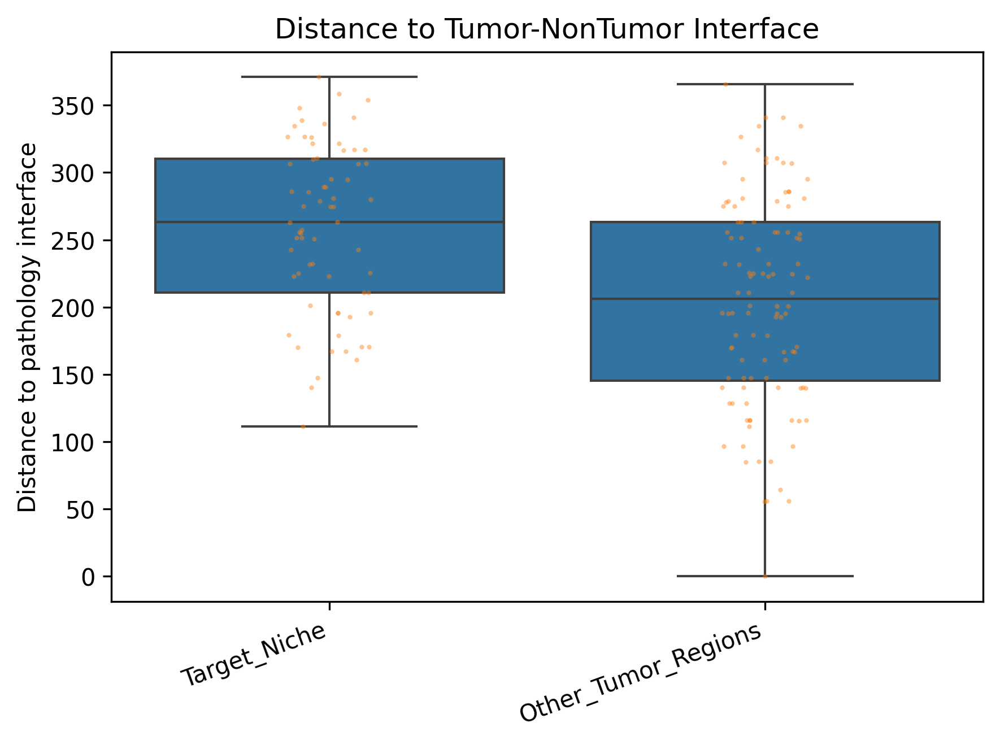

✅ 边界距离图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8C_TargetNiche_Distance_to_Pathology_Interface.png


In [8]:
# =========================================================
# Cell 6: 肿瘤边界 / tumor-normal interface 距离分析
# =========================================================
if "spatial" not in adata.obsm.keys():
    raise KeyError("❌ 缺少 adata.obsm['spatial']，无法进行边界距离分析。")

coords = np.asarray(adata.obsm["spatial"])
valid_mask = adata.obs["Pathology_Binary_ARI"].astype(str).isin(["Pathology_Tumor", "Pathology_Non_Tumor"]).values
pathology_is_tumor = (adata.obs["Pathology_Binary_ARI"].astype(str).values == "Pathology_Tumor")

# 对所有 valid spots 建 KNN
valid_indices = np.where(valid_mask)[0]
valid_coords = coords[valid_indices]
valid_tumor = pathology_is_tumor[valid_indices]

if len(valid_indices) <= KNN_K:
    raise ValueError("❌ 有效 spot 数不足，无法构建 KNN 边界。")

nbrs = NearestNeighbors(n_neighbors=min(KNN_K + 1, len(valid_indices)), metric="euclidean")
nbrs.fit(valid_coords)
distances, indices = nbrs.kneighbors(valid_coords)

# 去掉自身邻居
neighbor_indices = indices[:, 1:]

# 边界 spot：其邻居中至少有一个与自身病理类别不同
is_boundary_valid = np.zeros(len(valid_indices), dtype=bool)
for i in range(len(valid_indices)):
    neigh_tumor = valid_tumor[neighbor_indices[i]]
    is_boundary_valid[i] = np.any(neigh_tumor != valid_tumor[i])

boundary_global_indices = valid_indices[is_boundary_valid]
boundary_coords = coords[boundary_global_indices]

if len(boundary_global_indices) == 0:
    print("⚠️ 未检测到 Tumor/Non-Tumor 边界 spot，跳过边界距离分析。")
    adata.obs["Distance_to_Pathology_Interface"] = np.nan
else:
    interface_nbrs = NearestNeighbors(n_neighbors=1, metric="euclidean")
    interface_nbrs.fit(boundary_coords)
    dist_to_interface, _ = interface_nbrs.kneighbors(coords)
    adata.obs["Distance_to_Pathology_Interface"] = dist_to_interface[:, 0]

boundary_df = adata.obs[[
    "Pathology_Binary_ARI",
    "Level1_Macro_Region",
    "Level2_Micro_Niche",
    "Result8_Group",
    "Distance_to_Pathology_Interface",
]].copy()

boundary_csv = os.path.join(SAVE_DIR, "Result8_Distance_to_Pathology_Interface.csv")
boundary_df.to_csv(boundary_csv, encoding="utf-8-sig")
print("✅ 边界距离结果已保存：", boundary_csv)

# 统计比较：Target_Niche vs Other_Tumor_Regions
compare_df = boundary_df[
    boundary_df["Result8_Group"].astype(str).isin(["Target_Niche", "Other_Tumor_Regions"])
].dropna(subset=["Distance_to_Pathology_Interface"]).copy()

boundary_stats = []
if compare_df["Result8_Group"].nunique() == 2:
    a = compare_df.loc[compare_df["Result8_Group"].astype(str) == "Target_Niche", "Distance_to_Pathology_Interface"].values
    b = compare_df.loc[compare_df["Result8_Group"].astype(str) == "Other_Tumor_Regions", "Distance_to_Pathology_Interface"].values
    if len(a) > 1 and len(b) > 1:
        stat, pval = mannwhitneyu(a, b, alternative="two-sided")
    else:
        stat, pval = np.nan, np.nan
    boundary_stats.append({
        "comparison": "Target_Niche_vs_Other_Tumor_Regions",
        "target_n": len(a),
        "other_tumor_n": len(b),
        "target_mean_distance": np.nanmean(a),
        "other_tumor_mean_distance": np.nanmean(b),
        "target_median_distance": np.nanmedian(a),
        "other_tumor_median_distance": np.nanmedian(b),
        "mannwhitneyu_stat": stat,
        "mannwhitneyu_pvalue": pval,
    })

boundary_stats_df = pd.DataFrame(boundary_stats)
boundary_stats_csv = os.path.join(SAVE_DIR, "Result8_Boundary_Distance_Stats.csv")
boundary_stats_df.to_csv(boundary_stats_csv, index=False, encoding="utf-8-sig")
display(boundary_stats_df)

# 绘图
if len(compare_df) > 0:
    fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)
    if HAS_SEABORN:
        sns.boxplot(
            data=compare_df,
            x="Result8_Group",
            y="Distance_to_Pathology_Interface",
            order=["Target_Niche", "Other_Tumor_Regions"],
            ax=ax,
            showfliers=False,
        )
        sns.stripplot(
            data=compare_df,
            x="Result8_Group",
            y="Distance_to_Pathology_Interface",
            order=["Target_Niche", "Other_Tumor_Regions"],
            ax=ax,
            size=2,
            alpha=0.45,
        )
    else:
        vals = [
            compare_df.loc[compare_df["Result8_Group"].astype(str) == g, "Distance_to_Pathology_Interface"].values
            for g in ["Target_Niche", "Other_Tumor_Regions"]
        ]
        ax.boxplot(vals, labels=["Target_Niche", "Other_Tumor_Regions"], showfliers=False)
    ax.set_xlabel("")
    ax.set_ylabel("Distance to pathology interface")
    ax.set_title("Distance to Tumor-NonTumor Interface")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()

    boundary_fig = os.path.join(SAVE_DIR, "Fig8C_TargetNiche_Distance_to_Pathology_Interface.png")
    plt.savefig(boundary_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print("✅ 边界距离图已保存：", boundary_fig)
else:
    print("⚠️ 没有可用于边界距离比较的数据。")

## 表达矩阵预处理

后续三轴 score、DEG、ORA/GSEA 都使用原始 LC5.h5ad 的 17845 genes。  
这里复制一个 `adata_expr` 专门用于表达分析，避免影响前面用于空间图显示的 `adata`。

In [9]:
# =========================================================
# Cell 7: 表达矩阵预处理，用于 score / DEG / GSEA
# =========================================================
adata_expr = adata.copy()
adata_expr.var_names_make_unique()

if ASSUME_RAW_COUNTS:
    print("按照原始 counts 处理：normalize_total + log1p")
    sc.pp.normalize_total(adata_expr, target_sum=1e4)
    sc.pp.log1p(adata_expr)
else:
    print("ASSUME_RAW_COUNTS=False：不对 X 做 normalize_total/log1p")

print("✅ adata_expr 准备完成：")
print(adata_expr)

按照原始 counts 处理：normalize_total + log1p
✅ adata_expr 准备完成：
AnnData object with n_obs × n_vars = 622 × 17845
    obs: 'in_tissue', 'x_array', 'y_array', 'x_pixel', 'y_pixel', 'manual_anno', 'manual_anno_tls', 'aestetik_manual_anno', 'aestetik_manual_anno_tls', 'ground_truth', 'blur_score', 'Ground_Truth_Binary', 'Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Mast', 'Neutrophil', 'Unidentifiable', 'B cell naive', 'B cell non-switched memory', 'B cell switched memory', 'B cell exhausted', 'T CD4 naive', 'Th1', 'Th2', 'Th17', 'Tfh', 'Treg', 'T CD8 naive', 'T CD8 central memory', 'T CD8 effector memory', 'T CD8 effector', 'T CD8 exhausted', 'cDC1 CLEC9A', 'cDC2 CD1C', 'cDC3 LAMP3', 'Macrophage M1', 'Macrophage M2', 'Macrophage other', 'Pathology_Binary_ARI', 'Level1_Macro_Region', 'Level2_Micro_Niche', 'Is_Target_Niche', 'Result8_Group', 'Highlight_Multi_Axis_Lactate_Glutamine_LPA', 'Distance_to_Pathology_Interface'
    var: 'gene_

## 三轴共激活验证

优先使用最终 h5ad 中保留下来的 `Coupling_Lactate / Coupling_Glutamine / Coupling_LPA`。  
如果这些列不存在，则用 marker gene score 兜底计算：

- Lactate axis：糖酵解、乳酸生成/转运相关基因；
- Glutamine axis：谷氨酰胺摄取、代谢、TCA/redox 相关基因；
- LPA axis：ENPP2/ATX、LPARs、LPA-CAF/ECM 相关信号。

=== Cell 8: 重新计算 TuMeNiche 三轴 Coupling 分数 ===
✅ 用于重新计算 Coupling 的三条轴：


,TMCN_Name,Source_Pathways,Source_Genes,Target_Genes,Biologic_Meaning
0,TMCN_Lactate_Axis,"Hypoxia,EGFR,PI3K,MAPK","SLC2A1,HK2,PKM,LDHA,LDHB,SLC16A3","SLC16A1,SLC16A7,HCAR1,HCAR2",乳酸_肿瘤酸化瓦伯格效应与基质反向代谢共生
3,TMCN_Glutamine_Axis,"PI3K,MAPK,JAK-STAT,TGFb,WNT","GLUL,SLC38A1,SLC38A3,SLC38A5","SLC1A5,SLC7A5,SLC38A2,GLS,GLUD1",谷氨酰胺_基质向肿瘤供能的代谢寄生与大分子合成
8,TMCN_LPA_Axis,"PI3K,MAPK,TGFb","ENPP2,PLA2G4A,LPCAT1","LPAR1,LPAR2,LPAR3,LPAR5",溶血磷脂酸_成纤维细胞基质重塑与肿瘤高侵袭性



--> 1. 计算 Pathway_score：PROGENy MLM


✅ PROGENy pathway columns:
['Androgen', 'EGFR', 'Estrogen', 'Hypoxia', 'JAK_STAT', 'MAPK', 'NFkB', 'PI3K', 'TGFb', 'TNFa', 'Trail', 'VEGF', 'WNT', 'p53']

--> 2. 计算 Enzyme_score：AUCell(Source_Genes)
Source genes 匹配情况：


,Axis,Source_Genes_raw,Source_Genes_found,Source_Genes_missing
0,Lactate,"SLC2A1,HK2,PKM,LDHA,LDHB,SLC16A3","SLC2A1,HK2,SLC16A3","PKM,LDHA,LDHB"
1,Glutamine,"GLUL,SLC38A1,SLC38A3,SLC38A5","GLUL,SLC38A1,SLC38A3,SLC38A5",
2,LPA,"ENPP2,PLA2G4A,LPCAT1","ENPP2,PLA2G4A,LPCAT1",


✅ AUCell enzyme columns:
['Lactate', 'Glutamine', 'LPA']

--> 3. 计算 Sender_score 与 Receiver_score
✅ Sender/Receiver 输入匹配报告已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_RecomputedCoupling_InputGenePathway_Report.csv


,Axis,Valid_Source_Pathways,Missing_Source_Pathways,Target_Genes_raw,Target_Genes_found,Target_Genes_missing,Sender_mean,Receiver_mean
0,Lactate,"Hypoxia,EGFR,PI3K,MAPK",,"SLC16A1,SLC16A7,HCAR1,HCAR2","SLC16A1,SLC16A7,HCAR1,HCAR2",,0.047044,0.059850
1,Glutamine,"PI3K,MAPK,JAK_STAT,TGFb,WNT",,"SLC1A5,SLC7A5,SLC38A2,GLS,GLUD1","SLC1A5,SLC7A5,SLC38A2,GLS,GLUD1",,0.195828,0.285005
2,LPA,"PI3K,MAPK,TGFb",,"LPAR1,LPAR2,LPAR3,LPAR5","LPAR1,LPAR2,LPAR3,LPAR5",,0.281469,0.086938



--> 4. 构建空间邻接图并计算 Coupling
⚠️ adata 中没有 spatial_connectivities，使用 squidpy 重新构建 KNN 空间图：KNN_K=8
✅ 已重新计算三轴 Coupling：
{'Lactate': 'Coupling_Lactate', 'Glutamine': 'Coupling_Glutamine', 'LPA': 'Coupling_LPA'}
✅ 含重算 Coupling 的 Result8 h5ad 已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/LC5_Result8_with_Recomputed_Coupling.h5ad

--> 5. 统计 Target_Niche vs Other_Tumor_Regions 的三轴 Coupling 差异
✅ 三轴重算 Coupling 统计已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_ThreeAxis_RecomputedCoupling_Stats.csv


,Axis,Score_Column,Score_Type,Target_Niche_n,Other_Tumor_Regions_n,Target_Niche_mean,Other_Tumor_Regions_mean,Target_Niche_median,Other_Tumor_Regions_median,MannWhitneyU_stat,MannWhitneyU_pvalue
0,Lactate,Coupling_Lactate,Recomputed_TuMeNiche_Coupling,67,108,0.216968,0.016590,0.195743,0.000000,5825.5,3.883619e-14
1,Glutamine,Coupling_Glutamine,Recomputed_TuMeNiche_Coupling,67,108,0.451159,0.496626,0.470945,0.509219,3322.0,3.634866e-01
2,LPA,Coupling_LPA,Recomputed_TuMeNiche_Coupling,67,108,0.227532,0.246135,0.215654,0.230788,3368.5,4.446644e-01


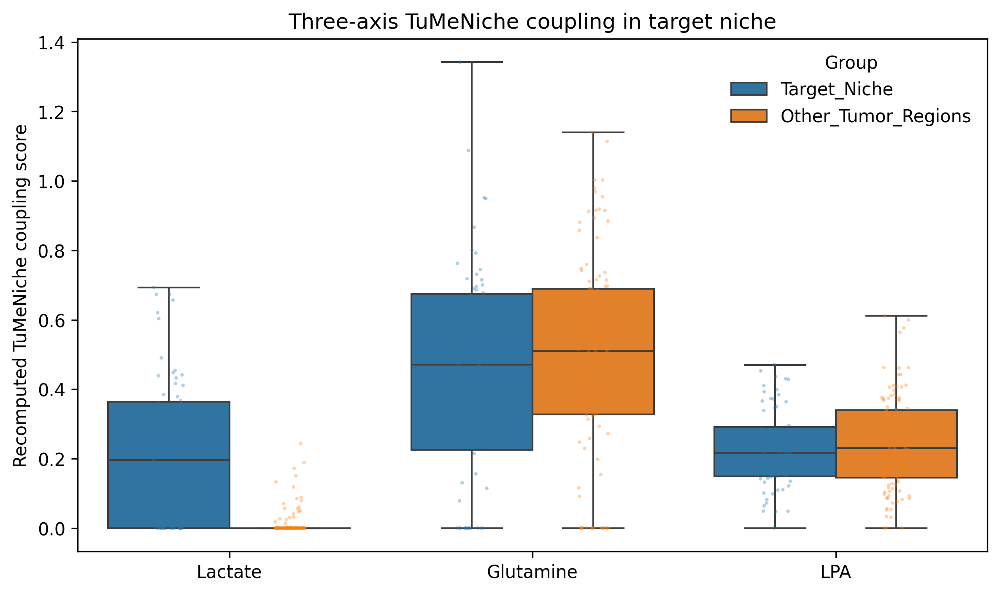

✅ 三轴重算 Coupling 图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8D_ThreeAxis_RecomputedCoupling_Target_vs_OtherTumor.png

✅ Cell 8 完成：后续 Result8 汇总会使用 score_stats_df 中的 Recomputed_TuMeNiche_Coupling 结果。


In [10]:
# =========================================================
# Cell 8: 三轴共激活验证 —— 按 TuMeNiche 原始 Coupling 公式重新计算
# 目的：
#   不再使用手工 marker gene set 兜底；
#   而是根据 TuMeNiche 四元组知识库重新计算：
#       Sender_score_k = PROGENy(Source_Pathways)_k × AUCell(Source_Genes)_k
#       Receiver_score_k = Target_Genes mean expression, MinMax-scaled
#       Coupling_k = log1p(Sender_score_k × Σ_j spatial_connectivity_ij × Receiver_score_j,k)
# =========================================================
import os
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.preprocessing import MinMaxScaler

try:
    import decoupler as dc
except Exception as e:
    raise ImportError(
        "❌ 当前环境没有成功导入 decoupler，无法按 TuMeNiche 原始方式计算 PROGENy/AUCell。\n"
        "请先确认当前 conda 环境中 decoupler 可用。"
    ) from e

print("=== Cell 8: 重新计算 TuMeNiche 三轴 Coupling 分数 ===")

# ---------------------------------------------------------
# 0. 配置：三条目标轴 + 四元组文件
# ---------------------------------------------------------
TARGET_AXES_FOR_COUPLING = ["Lactate", "Glutamine", "LPA"]

AXIS_TABLE_PATH = "/home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/siyuanzu/my_metabolite_network.csv"

if not os.path.exists(AXIS_TABLE_PATH):
    raise FileNotFoundError(f"❌ 未找到 TuMeNiche 四元组文件：{AXIS_TABLE_PATH}")

axis_table = pd.read_csv(AXIS_TABLE_PATH, encoding="utf-8-sig")

required_cols = ["TMCN_Name", "Source_Pathways", "Source_Genes", "Target_Genes", "Biologic_Meaning"]
missing_required = [c for c in required_cols if c not in axis_table.columns]
if len(missing_required) > 0:
    raise ValueError(f"❌ 四元组文件缺少必要列：{missing_required}")

for c in required_cols:
    axis_table[c] = axis_table[c].astype(str).str.strip()

axis_table["Axis"] = (
    axis_table["TMCN_Name"]
    .astype(str)
    .str.replace("TMCN_", "", regex=False)
    .str.replace("_Axis", "", regex=False)
)

axis_sub = axis_table[axis_table["Axis"].isin(TARGET_AXES_FOR_COUPLING)].copy()

if axis_sub.shape[0] != len(TARGET_AXES_FOR_COUPLING):
    found_axes = axis_sub["Axis"].tolist()
    missing_axes = [a for a in TARGET_AXES_FOR_COUPLING if a not in found_axes]
    raise ValueError(
        f"❌ 四元组文件中没有找到全部目标轴。\n"
        f"已找到：{found_axes}\n"
        f"缺失：{missing_axes}"
    )

print("✅ 用于重新计算 Coupling 的三条轴：")
display(axis_sub[["TMCN_Name", "Source_Pathways", "Source_Genes", "Target_Genes", "Biologic_Meaning"]])

# ---------------------------------------------------------
# 1. 工具函数
# ---------------------------------------------------------
def split_items(x):
    return [i.strip() for i in str(x).split(",") if i.strip() and i.strip().lower() != "nan"]

# 兼容部分新旧基因名，避免 CTGF/CCN2、CYR61/CCN1 这类命名导致漏匹配
GENE_ALIASES = {
    "CTGF": ["CTGF", "CCN2"],
    "CCN2": ["CCN2", "CTGF"],
    "CYR61": ["CYR61", "CCN1"],
    "CCN1": ["CCN1", "CYR61"],
}

def map_gene_symbols_to_varnames(adata_obj, genes):
    """大小写不敏感地把 gene symbol 映射到 adata.var_names 中真实存在的名称，并兼容少量别名。"""
    var_map = {str(v).upper(): str(v) for v in adata_obj.var_names}
    found = []
    missing = []

    for g in genes:
        gu = str(g).upper()
        candidates = [str(g)]
        if gu in GENE_ALIASES:
            candidates.extend(GENE_ALIASES[gu])

        hit = None
        for cand in candidates:
            cu = str(cand).upper()
            if cu in var_map:
                hit = var_map[cu]
                break

        if hit is not None and hit not in found:
            found.append(hit)
        elif hit is None:
            missing.append(g)

    return found, missing

def minmax_vector(x):
    x = np.asarray(x, dtype=float).reshape(-1)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    if np.nanmax(x) == np.nanmin(x):
        return np.zeros_like(x, dtype=float)
    return MinMaxScaler().fit_transform(x.reshape(-1, 1)).reshape(-1)

def get_mean_expr(adata_obj, genes):
    valid_genes, missing_genes = map_gene_symbols_to_varnames(adata_obj, genes)
    if len(valid_genes) == 0:
        return np.zeros(adata_obj.n_obs), valid_genes, missing_genes

    X_sub = adata_obj[:, valid_genes].X
    if sp.issparse(X_sub):
        mean_exp = np.asarray(X_sub.mean(axis=1)).reshape(-1)
    else:
        mean_exp = np.asarray(X_sub).mean(axis=1).reshape(-1)

    return mean_exp, valid_genes, missing_genes

# ---------------------------------------------------------
# 2. 表达矩阵选择
# ---------------------------------------------------------
# 这里使用 Cell 7 中已经 normalize_total + log1p 的 adata_expr。
# 这样比直接用 raw counts 更适合重新计算表达相关 score。
# 如果你想完全复刻原始 TuMeNiche notebook 对 adata 的直接计算，可把下一行改成：coupling_adata = adata.copy()
coupling_adata = adata_expr.copy()
coupling_adata.var_names_make_unique()

# 确保空间坐标存在
if "spatial" not in coupling_adata.obsm.keys():
    raise KeyError("❌ coupling_adata.obsm 中没有 spatial 坐标，无法计算空间 Coupling。")

# ---------------------------------------------------------
# 3. 计算 Pathway_score：PROGENy
# ---------------------------------------------------------
print("\n--> 1. 计算 Pathway_score：PROGENy MLM")
net_progeny = dc.get_progeny(organism="human", top=500)

dc.run_mlm(
    mat=coupling_adata,
    net=net_progeny,
    source="source",
    target="target",
    weight="weight",
    verbose=False,
    use_raw=False,
)

df_pathway = dc.get_acts(coupling_adata, obsm_key="mlm_estimate").to_df()
df_pathway.columns = [str(c).strip().replace("-", "_").replace(" ", "_") for c in df_pathway.columns]

df_pathway = df_pathway.replace([np.inf, -np.inf], np.nan).fillna(0.0)
df_pathway_scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(df_pathway),
    index=df_pathway.index,
    columns=df_pathway.columns,
)

print("✅ PROGENy pathway columns:")
print(df_pathway_scaled.columns.tolist())

# ---------------------------------------------------------
# 4. 计算 Enzyme_score：AUCell(Source_Genes)
# ---------------------------------------------------------
print("\n--> 2. 计算 Enzyme_score：AUCell(Source_Genes)")
enzyme_records = []
source_gene_report = []

for _, row in axis_sub.iterrows():
    axis = row["Axis"]
    source_genes_raw = split_items(row["Source_Genes"])
    source_genes_found, source_genes_missing = map_gene_symbols_to_varnames(coupling_adata, source_genes_raw)

    source_gene_report.append({
        "Axis": axis,
        "Source_Genes_raw": ",".join(source_genes_raw),
        "Source_Genes_found": ",".join(source_genes_found),
        "Source_Genes_missing": ",".join(source_genes_missing),
    })

    for g in source_genes_found:
        enzyme_records.append({"source": axis, "target": g})

source_gene_report_df = pd.DataFrame(source_gene_report)
print("Source genes 匹配情况：")
display(source_gene_report_df)

if len(enzyme_records) == 0:
    raise ValueError("❌ 三条轴的 Source_Genes 在表达矩阵中都没有匹配到，无法计算 AUCell。")

enzyme_net = pd.DataFrame(enzyme_records).drop_duplicates()

dc.run_aucell(
    mat=coupling_adata,
    net=enzyme_net,
    source="source",
    target="target",
    min_n=1,
    verbose=False,
    use_raw=False,
)

df_enzyme = dc.get_acts(coupling_adata, obsm_key="aucell_estimate").to_df()
df_enzyme = df_enzyme.replace([np.inf, -np.inf], np.nan).fillna(0.0)

# 如果某条轴没有 AUCell 输出，则补 0
for axis in TARGET_AXES_FOR_COUPLING:
    if axis not in df_enzyme.columns:
        df_enzyme[axis] = 0.0

df_enzyme = df_enzyme[TARGET_AXES_FOR_COUPLING]
df_enzyme_scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(df_enzyme),
    index=df_enzyme.index,
    columns=df_enzyme.columns,
)

print("✅ AUCell enzyme columns:")
print(df_enzyme_scaled.columns.tolist())

# ---------------------------------------------------------
# 5. 计算 Sender_score / Receiver_score
# ---------------------------------------------------------
print("\n--> 3. 计算 Sender_score 与 Receiver_score")
score_report = []

for _, row in axis_sub.iterrows():
    axis = row["Axis"]

    # Source_Pathways -> PROGENy pathway component
    source_pathways = [
        p.strip().replace("-", "_").replace(" ", "_")
        for p in split_items(row["Source_Pathways"])
    ]
    valid_pathways = [p for p in source_pathways if p in df_pathway_scaled.columns]
    missing_pathways = [p for p in source_pathways if p not in df_pathway_scaled.columns]

    if len(valid_pathways) == 0:
        # 不建议直接让整条轴变成 NaN；这里使用 1 作为 pathway fallback，使 Sender 由 enzyme component 决定。
        pathway_component = np.ones(coupling_adata.n_obs, dtype=float)
        print(f"⚠️ {axis}: Source_Pathways 未匹配到 PROGENy 列，使用 pathway_component=1 兜底。缺失：{missing_pathways}")
    else:
        pathway_component = df_pathway_scaled.loc[coupling_adata.obs_names, valid_pathways].mean(axis=1).values

    # Source_Genes -> enzyme component
    enzyme_component = df_enzyme_scaled.loc[coupling_adata.obs_names, axis].values

    sender_score = minmax_vector(pathway_component) * minmax_vector(enzyme_component)

    # Target_Genes -> receiver component
    target_genes_raw = split_items(row["Target_Genes"])
    receiver_mean, target_genes_found, target_genes_missing = get_mean_expr(coupling_adata, target_genes_raw)
    receiver_score = minmax_vector(receiver_mean)

    coupling_adata.obs[f"{axis}_Sender_Score_Recalc"] = sender_score
    coupling_adata.obs[f"{axis}_Receiver_Score_Recalc"] = receiver_score

    # 同步写回主对象
    adata.obs[f"{axis}_Sender_Score_Recalc"] = sender_score
    adata.obs[f"{axis}_Receiver_Score_Recalc"] = receiver_score
    adata_expr.obs[f"{axis}_Sender_Score_Recalc"] = sender_score
    adata_expr.obs[f"{axis}_Receiver_Score_Recalc"] = receiver_score

    score_report.append({
        "Axis": axis,
        "Valid_Source_Pathways": ",".join(valid_pathways),
        "Missing_Source_Pathways": ",".join(missing_pathways),
        "Target_Genes_raw": ",".join(target_genes_raw),
        "Target_Genes_found": ",".join(target_genes_found),
        "Target_Genes_missing": ",".join(target_genes_missing),
        "Sender_mean": float(np.nanmean(sender_score)),
        "Receiver_mean": float(np.nanmean(receiver_score)),
    })

score_report_df = pd.DataFrame(score_report)
score_report_csv = os.path.join(SAVE_DIR, "Result8_RecomputedCoupling_InputGenePathway_Report.csv")
score_report_df.to_csv(score_report_csv, index=False, encoding="utf-8-sig")
print("✅ Sender/Receiver 输入匹配报告已保存：", score_report_csv)
display(score_report_df)

# ---------------------------------------------------------
# 6. 构建空间邻接图，并重新计算 Coupling
# ---------------------------------------------------------
print("\n--> 4. 构建空间邻接图并计算 Coupling")
# 优先使用已有 spatial_connectivities；如果没有，则按 TuMeNiche 主流程使用 KNN=8 重新构建
if "spatial_connectivities" in adata.obsp.keys():
    adj_matrix = adata.obsp["spatial_connectivities"]
    print("✅ 使用 adata.obsp['spatial_connectivities'] 中已有空间邻接图")
else:
    print(f"⚠️ adata 中没有 spatial_connectivities，使用 squidpy 重新构建 KNN 空间图：KNN_K={KNN_K}")
    sq.gr.spatial_neighbors(
        coupling_adata,
        coord_type="generic",
        spatial_key="spatial",
        n_neighs=KNN_K,
    )
    adj_matrix = coupling_adata.obsp["spatial_connectivities"]

# 确保 CSR 格式，便于 dot
if not sp.issparse(adj_matrix):
    adj_matrix = sp.csr_matrix(adj_matrix)
else:
    adj_matrix = adj_matrix.tocsr()

axis_score_cols = {}

for axis in TARGET_AXES_FOR_COUPLING:
    sender_scores = coupling_adata.obs[f"{axis}_Sender_Score_Recalc"].values.astype(float)
    receiver_scores = coupling_adata.obs[f"{axis}_Receiver_Score_Recalc"].values.astype(float)

    neighbor_receiver_sum = adj_matrix.dot(receiver_scores)
    raw_coupling = sender_scores * neighbor_receiver_sum
    coupling_score = np.log1p(np.nan_to_num(raw_coupling, nan=0.0, posinf=0.0, neginf=0.0))

    col = f"Coupling_{axis}"
    coupling_adata.obs[col] = coupling_score
    adata.obs[col] = coupling_score
    adata_expr.obs[col] = coupling_score
    axis_score_cols[axis] = col

print("✅ 已重新计算三轴 Coupling：")
print(axis_score_cols)

# 保存带有重算 Coupling 的 Result8 h5ad，避免后续再次丢失
coupling_h5ad = os.path.join(SAVE_DIR, f"{SAMPLE_NAME}_Result8_with_Recomputed_Coupling.h5ad")
adata.write_h5ad(coupling_h5ad)
print("✅ 含重算 Coupling 的 Result8 h5ad 已保存：", coupling_h5ad)

# ---------------------------------------------------------
# 7. 统计 Target_Niche vs Other_Tumor_Regions
# ---------------------------------------------------------
print("\n--> 5. 统计 Target_Niche vs Other_Tumor_Regions 的三轴 Coupling 差异")
score_stats = []
score_long = []

compare_mask = adata.obs["Result8_Group"].astype(str).isin(["Target_Niche", "Other_Tumor_Regions"])

for axis, col in axis_score_cols.items():
    tmp = adata.obs.loc[compare_mask, ["Result8_Group", col]].copy()
    tmp = tmp.dropna(subset=[col])

    for _, row in tmp.iterrows():
        score_long.append({
            "Axis": axis,
            "Group": str(row["Result8_Group"]),
            "Score_Type": "Recomputed_TuMeNiche_Coupling",
            "Score": float(row[col]),
        })

    a = tmp.loc[tmp["Result8_Group"].astype(str) == "Target_Niche", col].values
    b = tmp.loc[tmp["Result8_Group"].astype(str) == "Other_Tumor_Regions", col].values

    if len(a) > 1 and len(b) > 1:
        stat, pval = mannwhitneyu(a, b, alternative="two-sided")
    else:
        stat, pval = np.nan, np.nan

    score_stats.append({
        "Axis": axis,
        "Score_Column": col,
        "Score_Type": "Recomputed_TuMeNiche_Coupling",
        "Target_Niche_n": len(a),
        "Other_Tumor_Regions_n": len(b),
        "Target_Niche_mean": np.nanmean(a) if len(a) > 0 else np.nan,
        "Other_Tumor_Regions_mean": np.nanmean(b) if len(b) > 0 else np.nan,
        "Target_Niche_median": np.nanmedian(a) if len(a) > 0 else np.nan,
        "Other_Tumor_Regions_median": np.nanmedian(b) if len(b) > 0 else np.nan,
        "MannWhitneyU_stat": stat,
        "MannWhitneyU_pvalue": pval,
    })

score_stats_df = pd.DataFrame(score_stats)
score_long_df = pd.DataFrame(score_long)

# 同时保存新名字和原来的名字，保证后续 Cell 13 汇总仍然读取 score_stats_df 变量
score_stats_csv = os.path.join(SAVE_DIR, "Result8_ThreeAxis_RecomputedCoupling_Stats.csv")
score_long_csv = os.path.join(SAVE_DIR, "Result8_ThreeAxis_RecomputedCoupling_LongTable.csv")
score_stats_df.to_csv(score_stats_csv, index=False, encoding="utf-8-sig")
score_long_df.to_csv(score_long_csv, index=False, encoding="utf-8-sig")

# 如果你希望覆盖原 GeneScore 文件，也保留一份同名输出
score_stats_df.to_csv(os.path.join(SAVE_DIR, "Result8_ThreeAxis_Coactivation_Stats.csv"), index=False, encoding="utf-8-sig")
score_long_df.to_csv(os.path.join(SAVE_DIR, "Result8_ThreeAxis_Coactivation_LongTable.csv"), index=False, encoding="utf-8-sig")

print("✅ 三轴重算 Coupling 统计已保存：", score_stats_csv)
display(score_stats_df)

# ---------------------------------------------------------
# 8. 绘图
# ---------------------------------------------------------
if len(score_long_df) > 0:
    fig, ax = plt.subplots(figsize=(8, 4.8), dpi=300)

    if HAS_SEABORN:
        sns.boxplot(
            data=score_long_df,
            x="Axis",
            y="Score",
            hue="Group",
            hue_order=["Target_Niche", "Other_Tumor_Regions"],
            order=TARGET_AXES_FOR_COUPLING,
            ax=ax,
            showfliers=False,
        )
        sns.stripplot(
            data=score_long_df,
            x="Axis",
            y="Score",
            hue="Group",
            hue_order=["Target_Niche", "Other_Tumor_Regions"],
            order=TARGET_AXES_FOR_COUPLING,
            dodge=True,
            ax=ax,
            size=2,
            alpha=0.35,
        )

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[:2], labels[:2], title="Group", frameon=False, loc="best")
    else:
        order = []
        vals = []
        for axis in TARGET_AXES_FOR_COUPLING:
            for group in ["Target_Niche", "Other_Tumor_Regions"]:
                sub = score_long_df[
                    (score_long_df["Axis"] == axis) &
                    (score_long_df["Group"] == group)
                ]["Score"].values
                if len(sub) > 0:
                    order.append(axis + "\n" + group)
                    vals.append(sub)
        ax.boxplot(vals, labels=order, showfliers=False)

    ax.set_title("Three-axis TuMeNiche coupling in target niche")
    ax.set_xlabel("")
    ax.set_ylabel("Recomputed TuMeNiche coupling score")
    plt.tight_layout()

    axis_fig = os.path.join(SAVE_DIR, "Fig8D_ThreeAxis_RecomputedCoupling_Target_vs_OtherTumor.png")
    plt.savefig(axis_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print("✅ 三轴重算 Coupling 图已保存：", axis_fig)

print("\n✅ Cell 8 完成：后续 Result8 汇总会使用 score_stats_df 中的 Recomputed_TuMeNiche_Coupling 结果。")


## SpaCET 细胞组成分析

这里比较 `Target_Niche`、`Other_Tumor_Regions` 和 `Healthy_Region` 的细胞组成，重点关注：

- Malignant：肿瘤相关性；
- CAF：LPA-CAF-ECM 重塑；
- Endothelial：血管生成；
- Macrophage / M2：免疫抑制性炎症微环境；
- T CD8 / T CD8 exhausted / Treg / NK：免疫抑制或免疫逃逸。

检测到的 SpaCET 细胞组成列：
['Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Macrophage M1', 'Macrophage M2', 'Mast', 'Neutrophil', 'Treg', 'T CD8 exhausted', 'T CD8 effector', 'T CD8 effector memory', 'Th1', 'Th2', 'Th17']
✅ 细胞组成均值表已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_CellFraction_Group_Mean.csv


,Malignant,CAF,Endothelial,Plasma,B cell,T CD4,T CD8,NK,cDC,pDC,...,Macrophage M2,Mast,Neutrophil,Treg,T CD8 exhausted,T CD8 effector,T CD8 effector memory,Th1,Th2,Th17
Result8_Group,,,,,,,,,,,,,,,,,,,,,
Target_Niche,0.869747,0.033174,0.000025,0.006827,0.000794,0.003815,0.000165,0.000253,0.001291,0.002649,...,0.006232,0.000879,0.003502,0.000999,0.000032,0.000032,0.000032,0.000092,0.000668,0.000968
Other_Tumor_Regions,0.849722,0.022148,0.043087,0.010604,0.002202,0.004035,0.000635,0.000755,0.005482,0.007078,...,0.011067,0.000714,0.000862,0.001438,0.000254,0.000096,0.000056,0.000286,0.000498,0.000563
Healthy_Region,0.408747,0.104644,0.105022,0.026257,0.013498,0.023603,0.005610,0.002218,0.017509,0.031924,...,0.136736,0.001203,0.002543,0.004899,0.001029,0.000655,0.000306,0.001390,0.003149,0.003393


✅ 细胞组成差异统计已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_CellFraction_Target_vs_OtherTumor_Stats.csv


,cell_type,target_mean,other_tumor_mean,target_median,other_tumor_median,target_minus_other_mean,mannwhitneyu_pvalue,padj
0,Malignant,0.869747,0.849722,8.831488e-01,8.487085e-01,0.020025,1.354529e-01,0.219917
1,CAF,0.033174,0.022148,2.111939e-06,3.297318e-04,0.011026,1.399471e-01,0.219917
14,Neutrophil,0.003502,0.000862,1.400678e-05,6.362888e-07,0.002640,3.223524e-01,0.393986
21,Th17,0.000968,0.000563,0.000000e+00,0.000000e+00,0.000405,9.059082e-01,0.905908
20,Th2,0.000668,0.000498,0.000000e+00,0.000000e+00,0.000170,7.030246e-01,0.814028
13,Mast,0.000879,0.000714,6.451972e-06,5.673491e-06,0.000165,2.402644e-01,0.310930
18,T CD8 effector memory,0.000032,0.000056,0.000000e+00,0.000000e+00,-0.000024,1.515640e-02,0.027787
17,T CD8 effector,0.000032,0.000096,0.000000e+00,0.000000e+00,-0.000063,1.397338e-02,0.027787
19,Th1,0.000092,0.000286,0.000000e+00,0.000000e+00,-0.000194,8.612331e-01,0.905908
5,T CD4,0.003815,0.004035,2.786381e-06,6.028609e-06,-0.000220,1.563361e-01,0.219952


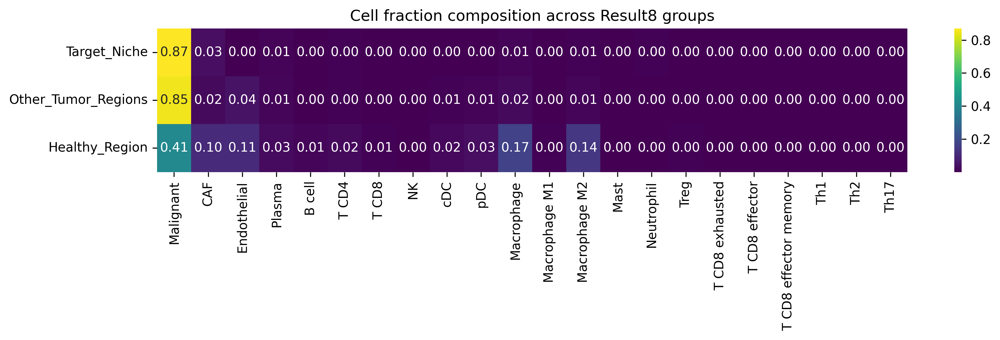

✅ 细胞组成热图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8E_CellFraction_Heatmap_Result8_Groups.png


In [11]:
# =========================================================
# Cell 9: SpaCET 细胞组成分析
# =========================================================
cell_type_candidates = [
    "Malignant",
    "CAF",
    "Endothelial",
    "Plasma",
    "B cell",
    "T CD4",
    "T CD8",
    "NK",
    "cDC",
    "pDC",
    "Macrophage",
    "Macrophage M1",
    "Macrophage M2",
    "Mast",
    "Neutrophil",
    "Treg",
    "T CD8 exhausted",
    "T CD8 effector",
    "T CD8 effector memory",
    "Th1",
    "Th2",
    "Th17",
]

cell_cols = [c for c in cell_type_candidates if c in adata.obs.columns]
print("检测到的 SpaCET 细胞组成列：")
print(cell_cols)

if len(cell_cols) == 0:
    print("⚠️ 没有检测到 SpaCET 细胞组成列，跳过细胞组成分析。")
    cell_mean_df = pd.DataFrame()
    cell_stats_df = pd.DataFrame()
else:
    cell_df = adata.obs[["Result8_Group"] + cell_cols].copy()
    for c in cell_cols:
        cell_df[c] = pd.to_numeric(cell_df[c], errors="coerce")

    cell_mean_df = (
        cell_df
        .groupby("Result8_Group", observed=True)[cell_cols]
        .mean()
        .reindex(["Target_Niche", "Other_Tumor_Regions", "Healthy_Region"])
    )

    cell_mean_csv = os.path.join(SAVE_DIR, "Result8_CellFraction_Group_Mean.csv")
    cell_mean_df.to_csv(cell_mean_csv, encoding="utf-8-sig")
    print("✅ 细胞组成均值表已保存：", cell_mean_csv)
    display(cell_mean_df)

    # Target_Niche vs Other_Tumor_Regions 统计检验
    cell_stats = []
    for c in cell_cols:
        a = cell_df.loc[cell_df["Result8_Group"].astype(str) == "Target_Niche", c].dropna().values
        b = cell_df.loc[cell_df["Result8_Group"].astype(str) == "Other_Tumor_Regions", c].dropna().values
        if len(a) > 1 and len(b) > 1:
            stat, pval = mannwhitneyu(a, b, alternative="two-sided")
        else:
            stat, pval = np.nan, np.nan
        cell_stats.append({
            "cell_type": c,
            "target_mean": np.nanmean(a) if len(a) > 0 else np.nan,
            "other_tumor_mean": np.nanmean(b) if len(b) > 0 else np.nan,
            "target_median": np.nanmedian(a) if len(a) > 0 else np.nan,
            "other_tumor_median": np.nanmedian(b) if len(b) > 0 else np.nan,
            "target_minus_other_mean": (np.nanmean(a) - np.nanmean(b)) if len(a) > 0 and len(b) > 0 else np.nan,
            "mannwhitneyu_pvalue": pval,
        })
    cell_stats_df = pd.DataFrame(cell_stats)
    if cell_stats_df["mannwhitneyu_pvalue"].notna().any():
        mask = cell_stats_df["mannwhitneyu_pvalue"].notna()
        cell_stats_df.loc[mask, "padj"] = multipletests(
            cell_stats_df.loc[mask, "mannwhitneyu_pvalue"].values,
            method="fdr_bh"
        )[1]
    else:
        cell_stats_df["padj"] = np.nan

    cell_stats_df = cell_stats_df.sort_values("target_minus_other_mean", ascending=False)
    cell_stats_csv = os.path.join(SAVE_DIR, "Result8_CellFraction_Target_vs_OtherTumor_Stats.csv")
    cell_stats_df.to_csv(cell_stats_csv, index=False, encoding="utf-8-sig")
    print("✅ 细胞组成差异统计已保存：", cell_stats_csv)
    display(cell_stats_df.head(20))

    # 热图：展示均值
    fig, ax = plt.subplots(figsize=(max(8, len(cell_cols) * 0.55), 3.8), dpi=300)
    if HAS_SEABORN:
        sns.heatmap(cell_mean_df[cell_cols], cmap="viridis", annot=True, fmt=".2f", ax=ax)
    else:
        im = ax.imshow(cell_mean_df[cell_cols].values, aspect="auto")
        ax.set_xticks(np.arange(len(cell_cols)))
        ax.set_xticklabels(cell_cols, rotation=45, ha="right")
        ax.set_yticks(np.arange(cell_mean_df.shape[0]))
        ax.set_yticklabels(cell_mean_df.index)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title("Cell fraction composition across Result8 groups")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout()

    cell_fig = os.path.join(SAVE_DIR, "Fig8E_CellFraction_Heatmap_Result8_Groups.png")
    plt.savefig(cell_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print("✅ 细胞组成热图已保存：", cell_fig)

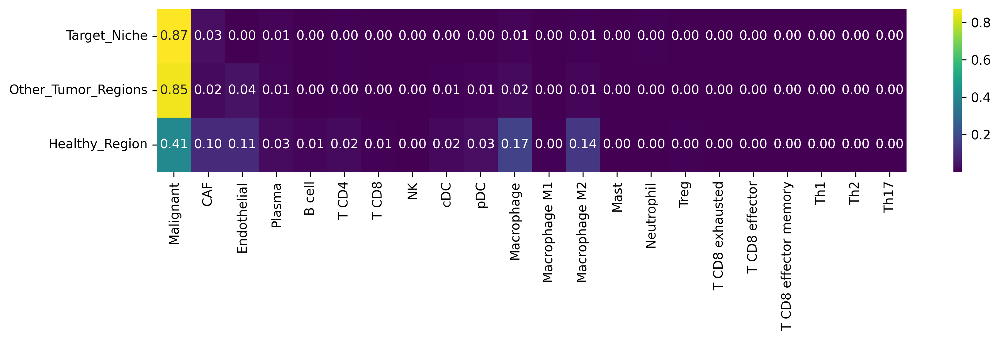

✅ 无标题细胞组成热图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8E_CellFraction_Heatmap_Result8_Groups_no_title.png


In [12]:
# =========================================================
# Cell 9.1: SpaCET 细胞组成热图 - 无标题版本
# =========================================================

if "cell_mean_df" not in globals() or cell_mean_df.empty:
    print("⚠️ cell_mean_df 不存在或为空，请先运行 Cell 9。")
elif "cell_cols" not in globals() or len(cell_cols) == 0:
    print("⚠️ cell_cols 不存在或为空，请先运行 Cell 9。")
else:
    fig, ax = plt.subplots(
        figsize=(max(8, len(cell_cols) * 0.55), 3.8),
        dpi=300
    )

    if HAS_SEABORN:
        sns.heatmap(
            cell_mean_df[cell_cols],
            cmap="viridis",
            annot=True,
            fmt=".2f",
            ax=ax
        )
    else:
        im = ax.imshow(cell_mean_df[cell_cols].values, aspect="auto")
        ax.set_xticks(np.arange(len(cell_cols)))
        ax.set_xticklabels(cell_cols, rotation=90, ha="center")
        ax.set_yticks(np.arange(cell_mean_df.shape[0]))
        ax.set_yticklabels(cell_mean_df.index)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # 不显示标题和坐标轴标题
    ax.set_title("")
    ax.set_xlabel("")
    ax.set_ylabel("")

    # 保持 x 轴标签竖排，避免重叠
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="center")

    plt.tight_layout()

    cell_fig_no_title = os.path.join(
        SAVE_DIR,
        "Fig8E_CellFraction_Heatmap_Result8_Groups_no_title.png"
    )
    plt.savefig(cell_fig_no_title, dpi=300, bbox_inches="tight")
    plt.show()

    print("✅ 无标题细胞组成热图已保存：", cell_fig_no_title)

## DEG：Target_Niche vs Other_Tumor_Regions

这里使用原始 LC5.h5ad 的 17845 genes 表达矩阵，比较：

```text
Multi_Axis_Lactate_Glutamine_LPA
vs
Other_Tumor_Regions
```

这样避免把差异简单写成“肿瘤 vs 正常”，而是强调**肿瘤内部三轴混合生态位的特殊功能状态**。

DEG group counts:
Other_Tumor_Regions    108
Target_Niche            67
Name: DEG_Group, dtype: int64
✅ DEG 结果已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/DEG_TargetNiche_vs_OtherTumorRegions_AllGenes.csv


,gene,score,logfoldchanges,pval,padj,pct_nz_group,padj_safe,neglog10_padj,ranking_score
0,CCN2,8.401558,1.340459,4.405951e-17,1.965605e-13,1.000000,1.965605e-13,12.706504,17.032543
1,HIF3A,8.174405,1.795243,2.973283e-16,7.579748e-13,0.970149,7.579748e-13,12.120345,21.758967
2,SLC2A1,8.131431,2.801865,4.242528e-16,9.463490e-13,0.895522,9.463490e-13,12.023949,33.689485
3,HSP90AA1,7.931905,1.022734,2.158090e-15,4.279013e-12,1.000000,4.279013e-12,11.368656,11.627115
4,GNB1,7.826003,0.831643,5.036241e-15,8.987173e-12,0.985075,8.987173e-12,11.046377,9.186643
5,PHACTR3,7.585038,1.689698,3.323899e-14,4.442138e-11,1.000000,4.442138e-11,10.352408,17.492440
6,CRLF1,7.578898,1.402910,3.485006e-14,4.442138e-11,1.000000,4.442138e-11,10.352408,14.523495
7,KRT18,7.474532,1.196940,7.747940e-14,7.681221e-11,1.000000,7.681221e-11,10.114570,12.106536
8,STAT3,7.423882,1.292191,1.137359e-13,1.014808e-10,0.985075,1.014808e-10,9.993616,12.913662
9,ERRFI1,7.348677,1.179233,2.001783e-13,1.623719e-10,1.000000,1.623719e-10,9.789489,11.544090


显著上调基因数: 270
显著下调基因数: 375


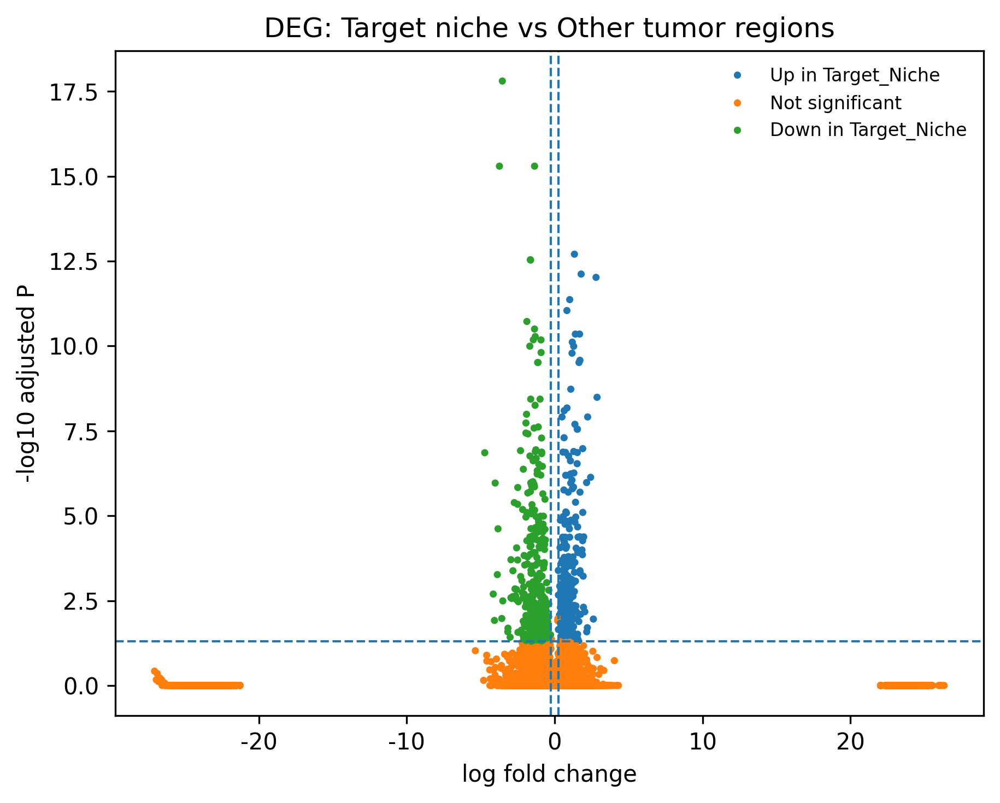

✅ 火山图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8F_DEG_Volcano_Target_vs_OtherTumor.png


In [13]:
# =========================================================
# Cell 10: DEG - Target_Niche vs Other_Tumor_Regions
# =========================================================
deg_mask = adata_expr.obs["Result8_Group"].astype(str).isin(["Target_Niche", "Other_Tumor_Regions"])
adata_deg = adata_expr[deg_mask].copy()
adata_deg.obs["DEG_Group"] = adata_deg.obs["Result8_Group"].astype(str)
adata_deg.obs["DEG_Group"] = pd.Categorical(
    adata_deg.obs["DEG_Group"],
    categories=["Target_Niche", "Other_Tumor_Regions"],
    ordered=True,
)

print("DEG group counts:")
print(adata_deg.obs["DEG_Group"].value_counts())

if adata_deg.obs["DEG_Group"].value_counts().min() < 3:
    print("⚠️ 某一组 spot 数少于 3，DEG 结果可能不稳定。")

# 使用 Wilcoxon，适合 spot-level 非参数比较
sc.tl.rank_genes_groups(
    adata_deg,
    groupby="DEG_Group",
    groups=["Target_Niche"],
    reference="Other_Tumor_Regions",
    method="wilcoxon",
    pts=True,
    corr_method="benjamini-hochberg",
)

deg_df = sc.get.rank_genes_groups_df(adata_deg, group="Target_Niche")

# 统一列名
rename_map = {
    "names": "gene",
    "scores": "score",
    "logfoldchanges": "logfoldchanges",
    "pvals": "pval",
    "pvals_adj": "padj",
}
deg_df = deg_df.rename(columns=rename_map)

# 添加 ranking score，用于 prerank GSEA
# 注意 padj 可能为 0，使用极小值避免 inf
deg_df["padj_safe"] = deg_df["padj"].replace(0, 1e-300)
deg_df["neglog10_padj"] = -np.log10(deg_df["padj_safe"])
deg_df["ranking_score"] = deg_df["logfoldchanges"].fillna(0) * deg_df["neglog10_padj"].fillna(0)

deg_csv = os.path.join(SAVE_DIR, "DEG_TargetNiche_vs_OtherTumorRegions_AllGenes.csv")
deg_df.to_csv(deg_csv, index=False, encoding="utf-8-sig")

print("✅ DEG 结果已保存：", deg_csv)
display(deg_df.head(20))

# 保存显著上调/下调基因
up_df = deg_df[(deg_df["padj"] < DEG_PADJ_CUTOFF) & (deg_df["logfoldchanges"] > DEG_LOGFC_CUTOFF)].copy()
down_df = deg_df[(deg_df["padj"] < DEG_PADJ_CUTOFF) & (deg_df["logfoldchanges"] < -DEG_LOGFC_CUTOFF)].copy()

up_csv = os.path.join(SAVE_DIR, "DEG_TargetNiche_vs_OtherTumorRegions_UpGenes.csv")
down_csv = os.path.join(SAVE_DIR, "DEG_TargetNiche_vs_OtherTumorRegions_DownGenes.csv")
up_df.to_csv(up_csv, index=False, encoding="utf-8-sig")
down_df.to_csv(down_csv, index=False, encoding="utf-8-sig")

print(f"显著上调基因数: {len(up_df)}")
print(f"显著下调基因数: {len(down_df)}")

# Volcano plot
fig, ax = plt.subplots(figsize=(6.2, 5), dpi=300)
plot_df = deg_df.copy()
plot_df["minus_log10_padj"] = -np.log10(plot_df["padj"].replace(0, 1e-300))
plot_df["significance"] = "Not significant"
plot_df.loc[(plot_df["padj"] < DEG_PADJ_CUTOFF) & (plot_df["logfoldchanges"] > DEG_LOGFC_CUTOFF), "significance"] = "Up in Target_Niche"
plot_df.loc[(plot_df["padj"] < DEG_PADJ_CUTOFF) & (plot_df["logfoldchanges"] < -DEG_LOGFC_CUTOFF), "significance"] = "Down in Target_Niche"

if HAS_SEABORN:
    sns.scatterplot(
        data=plot_df,
        x="logfoldchanges",
        y="minus_log10_padj",
        hue="significance",
        s=10,
        linewidth=0,
        ax=ax,
    )
    ax.legend(frameon=False, fontsize=8)
else:
    ax.scatter(plot_df["logfoldchanges"], plot_df["minus_log10_padj"], s=8, alpha=0.6)

ax.axvline(DEG_LOGFC_CUTOFF, linestyle="--", linewidth=1)
ax.axvline(-DEG_LOGFC_CUTOFF, linestyle="--", linewidth=1)
ax.axhline(-np.log10(DEG_PADJ_CUTOFF), linestyle="--", linewidth=1)
ax.set_xlabel("log fold change")
ax.set_ylabel("-log10 adjusted P")
ax.set_title("DEG: Target niche vs Other tumor regions")
plt.tight_layout()

volcano_png = os.path.join(SAVE_DIR, "Fig8F_DEG_Volcano_Target_vs_OtherTumor.png")
plt.savefig(volcano_png, dpi=300, bbox_inches="tight")
plt.show()
print("✅ 火山图已保存：", volcano_png)

## ORA / GSEA 功能富集

使用本地 MSigDB GMT：

```text
/home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB
```

重点关注与 Result 8 机制相关的功能：

- Glycolysis / Hypoxia / Lactate
- Glutamine metabolism / TCA / redox
- LPA / ATX / YAP / CAF / ECM
- EMT / migration / invasion
- Angiogenesis
- Immune suppression / inflammation
- TGF-beta / PI3K-AKT / MAPK

检测到/选择的 GMT 文件：
 - /home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB/h.all.v2026.1.Hs.symbols.gmt
 - /home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB/c2.cp.reactome.v2026.1.Hs.symbols.gmt
 - /home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB/c2.cp.v2026.1.Hs.symbols.gmt
共读取 gene sets: 6004
背景基因数: 17845
显著上调基因数: 270
Prerank input 已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/GSEA_Prerank_Input_Target_vs_OtherTumor.csv
✅ ORA 结果已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/ORA_TargetNiche_UpGenes_vs_OtherTumor.csv


,term,overlap_count,gene_set_size_in_background,up_gene_count,background_gene_count,pvalue,overlap_genes,padj,neglog10_padj
214,REACTOME_DENGUE_VIRUS_INFECTION,31,341,270,17845,1.061706e-15,CANX;DDX5;EIF4A2;H2AC11;H2AC13;H3C10;H4C3;HNRN...,1.584065e-12,11.800227
1702,c2.cp.v2026.1.Hs.symbols::REACTOME_DENGUE_VIRU...,31,341,270,17845,1.061706e-15,CANX;DDX5;EIF4A2;H2AC11;H2AC13;H3C10;H4C3;HNRN...,1.584065e-12,11.800227
30,HALLMARK_MYC_TARGETS_V1,22,164,270,17845,6.137428e-15,CANX;CCT3;CCT5;DEK;HDAC2;HNRNPA2B1;HNRNPC;HSP9...,5.799763e-12,11.236590
407,REACTOME_INFECTIOUS_DISEASE,53,1064,270,17845,9.718102e-15,ATP1A1;ATP1B1;C3;CALM3;CANX;CEBPD;COL5A1;DDX5;...,5.799763e-12,11.236590
1895,c2.cp.v2026.1.Hs.symbols::REACTOME_INFECTIOUS_...,53,1064,270,17845,9.718102e-15,ATP1A1;ATP1B1;C3;CALM3;CANX;CEBPD;COL5A1;DDX5;...,5.799763e-12,11.236590
992,REACTOME_VIRAL_INFECTION_PATHWAYS,45,854,270,17845,1.975833e-13,ATP1A1;ATP1B1;CANX;CEBPD;DDX5;EIF4A2;GJA1;H2AC...,8.422694e-11,10.074549
2480,c2.cp.v2026.1.Hs.symbols::REACTOME_VIRAL_INFEC...,45,854,270,17845,1.975833e-13,ATP1A1;ATP1B1;CANX;CEBPD;DDX5;EIF4A2;GJA1;H2AC...,8.422694e-11,10.074549
142,REACTOME_CELLULAR_RESPONSES_TO_STIMULI,39,738,270,17845,8.973954e-12,COX7A2;COX7C;CXCL8;DNAJB1;EGLN3;ERO1A;FOS;GJA1...,2.975364e-09,8.526460
1630,c2.cp.v2026.1.Hs.symbols::REACTOME_CELLULAR_RE...,39,738,270,17845,8.973954e-12,COX7A2;COX7C;CXCL8;DNAJB1;EGLN3;ERO1A;FOS;GJA1...,2.975364e-09,8.526460
20,HALLMARK_HYPOXIA,20,190,270,17845,1.078343e-11,CCN2;CDKN1C;COL5A1;DDIT4;ENO1;ERO1A;ERRFI1;F3;...,3.217776e-09,8.492444


✅ Result 8 机制相关 ORA 通路已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/ORA_TargetNiche_Focus_Pathways.csv


,term,overlap_count,gene_set_size_in_background,up_gene_count,background_gene_count,pvalue,overlap_genes,padj,neglog10_padj
20,HALLMARK_HYPOXIA,20,190,270,17845,1.078343e-11,CCN2;CDKN1C;COL5A1;DDIT4;ENO1;ERO1A;ERRFI1;F3;...,3.217776e-09,8.492444
29,HALLMARK_MTORC1_SIGNALING,17,173,270,17845,1.162894e-09,CANX;DDIT4;EGLN3;ENO1;ERO1A;FADS1;GPI;HSPD1;HS...,2.313383e-07,6.635752
417,REACTOME_INNATE_IMMUNE_SYSTEM,41,974,270,17845,2.549021e-09,C3;CALM3;CFB;COPB1;CPNE1;CSTB;DNM2;EEF2;FOS;FT...,4.474281e-07,6.349277
1905,c2.cp.v2026.1.Hs.symbols::REACTOME_INNATE_IMMU...,41,974,270,17845,2.549021e-09,C3;CALM3;CFB;COPB1;CPNE1;CSTB;DNM2;EEF2;FOS;FT...,4.474281e-07,6.349277
193,REACTOME_CYTOKINE_SIGNALING_IN_IMMUNE_SYSTEM,30,717,270,17845,4.874174e-07,CANX;CEBPD;CRLF1;CXCL8;EIF4A2;FOS;H3C10;HNRNPA...,4.040149e-05,4.393603
1681,c2.cp.v2026.1.Hs.symbols::REACTOME_CYTOKINE_SI...,30,717,270,17845,4.874174e-07,CANX;CEBPD;CRLF1;CXCL8;EIF4A2;FOS;H3C10;HNRNPA...,4.040149e-05,4.393603
12,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,14,189,270,17845,1.156126e-06,CADM1;CCN2;COL5A1;COL6A3;CRLF1;CXCL8;FSTL1;GJA...,8.214002e-05,4.085445
693,REACTOME_REGULATION_OF_HOMOTYPIC_CELL_CELL_ADH...,12,184,270,17845,2.451385e-05,CANX;CTNNA1;DNM2;H3-3B;H3C10;H4C3;HDAC2;JUP;PS...,9.362213e-04,3.028621
2181,c2.cp.v2026.1.Hs.symbols::REACTOME_REGULATION_...,12,184,270,17845,2.451385e-05,CANX;CTNNA1;DNM2;H3-3B;H3C10;H4C3;HDAC2;JUP;PS...,9.362213e-04,3.028621
2513,WP_AEROBIC_GLYCOLYSIS_AUGMENTED,3,8,270,17845,1.813377e-04,ENO1;GPI;SLC2A1,3.559945e-03,2.448557


2026-11-15 16:14:21,605 [WARNING] Duplicated values found in preranked stats: 83.27% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


检测到 gseapy，开始 prerank GSEA...
✅ GSEA prerank 结果已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/GSEA_Prerank_TargetNiche_vs_OtherTumor.csv


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,KEGG_MEDICUS_PATHOGEN_SARS_COV_2_S_TO_CLASSICA...,-0.97259,-1.85219,0.101078,1.0,0.932,4/5,2.77%,C1QB;C1QC;C1R;C1QA
1,prerank,KEGG_MEDICUS_REFERENCE_GLYCOGEN_DEGRADATION_AM...,-0.980886,-1.837342,0.06516,1.0,0.985,1/5,1.92%,GAA
2,prerank,KEGG_MEDICUS_PATHOGEN_SHIGELLA_IPGB1_TO_ITGA_B...,-0.977466,-1.836963,0.079747,1.0,0.985,2/5,2.27%,RAC1;DOCK1
3,prerank,KEGG_MEDICUS_PATHOGEN_SALMONELLA_SOPB_TO_RHOG_...,-0.986883,-1.827271,0.045396,1.0,0.995,1/5,1.32%,RHOG
4,prerank,REACTOME_DEFECTIVE_CSF2RB_CAUSES_SMDP5,-0.9912,-1.821413,0.03125,1.0,0.997,3/5,0.90%,SFTPB;SFTPD;SFTPC
5,prerank,c2.cp.v2026.1.Hs.symbols::REACTOME_DEFECTIVE_C...,-0.9912,-1.821413,0.03125,1.0,0.997,3/5,0.90%,SFTPB;SFTPD;SFTPC
6,prerank,KEGG_MEDICUS_VARIANT_MUTATION_CAUSED_ABERRANT_...,-0.987724,-1.816375,0.048,1.0,0.999,1/5,1.24%,HTT
7,prerank,KEGG_MEDICUS_PATHOGEN_EBV_LMP2A_TO_PI3K_SIGNAL...,-0.967713,-1.8157,0.114286,1.0,1.0,1/5,3.24%,PIK3CB
8,prerank,WP_MITOCHONDRIAL_FATTY_ACID_SYNTHESIS_PATHWAY,-0.961211,-1.805481,0.149867,1.0,1.0,1/5,3.89%,MCAT
9,prerank,KEGG_MEDICUS_PATHOGEN_KSHV_MIR1_2_TO_ANTIGEN_P...,-0.982904,-1.795492,0.05548,1.0,1.0,4/5,1.74%,HLA-E;HLA-G;HLA-F;HLA-C


✅ Result 8 机制相关 GSEA 通路已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/GSEA_Prerank_TargetNiche_Focus_Pathways.csv


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
7,prerank,KEGG_MEDICUS_PATHOGEN_EBV_LMP2A_TO_PI3K_SIGNAL...,-0.967713,-1.8157,0.114286,1.0,1.0,1/5,3.24%,PIK3CB
38,prerank,WP_SARSCOV2_ALTERING_ANGIOGENESIS_VIA_NRP1,-0.96065,-1.738173,0.132732,0.960372,1.0,1/5,3.95%,FURIN
53,prerank,KEGG_MEDICUS_PATHOGEN_EBV_LMP1_TO_PI3K_SIGNALI...,-0.967769,-1.707451,0.11869,0.997794,1.0,2/5,3.24%,TRAF5;PIK3CB
137,prerank,KEGG_MEDICUS_PATHOGEN_YERSINIA_YOPP_J_TO_TLR2_...,-0.934077,-1.604522,0.295486,0.9163,1.0,1/6,6.60%,MAP2K7
148,prerank,KEGG_MEDICUS_REFERENCE_ACH_CHRN_PI3K_SIGNALING...,-0.967709,-1.593924,0.148936,0.89745,1.0,1/7,3.24%,PIK3CB
182,prerank,c2.cp.v2026.1.Hs.symbols::REACTOME_ENHANCED_BI...,-0.985873,-1.566579,0.05571,0.844727,1.0,1/7,1.42%,COL1A2
183,prerank,REACTOME_ENHANCED_BINDING_OF_GP1BA_VARIANT_TO_...,-0.985873,-1.566579,0.05571,0.844727,1.0,1/7,1.42%,COL1A2
199,prerank,REACTOME_IFNG_SIGNALING_ACTIVATES_MAPKS,-0.990077,-1.539173,0.029536,0.885273,1.0,1/8,1.00%,IFNGR2
200,prerank,c2.cp.v2026.1.Hs.symbols::REACTOME_IFNG_SIGNAL...,-0.990077,-1.539173,0.029536,0.885273,1.0,1/8,1.00%,IFNGR2
220,prerank,KEGG_MEDICUS_VARIANT_MUTATION_ACTIVATED_KIT_TO...,-0.967708,-1.521702,0.174699,0.88691,1.0,1/8,3.24%,PIK3CB


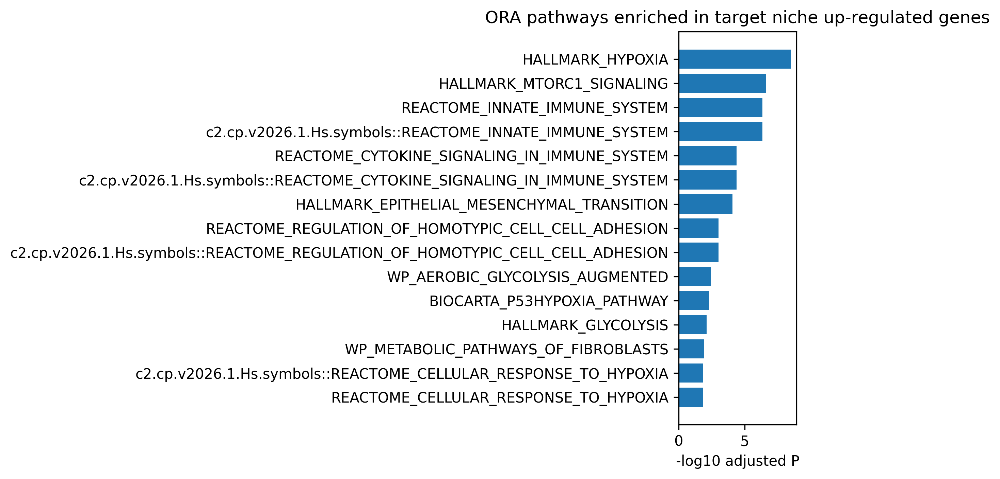

✅ ORA 通路图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8G_ORA_TargetNiche_Focus_Pathways.png


In [14]:
# =========================================================
# Cell 11: 本地 GMT 解析 + ORA + 可选 GSEA prerank
# =========================================================
def find_gmt_files(gmt_dir):
    gmt_dir = Path(gmt_dir)
    if not gmt_dir.exists():
        print(f"⚠️ GMT_DIR 不存在：{gmt_dir}")
        return []
    all_gmts = sorted(gmt_dir.rglob("*.gmt"))
    # 优先选择 Hallmark / Reactome / GO Biological Process / KEGG 等常用集合
    prefer_keywords = [
        "h.all",
        "c2.cp.reactome",
        "c2.cp.kegg",
        "c5.go.bp",
        "c2.cp",
    ]
    selected = []
    for kw in prefer_keywords:
        selected.extend([p for p in all_gmts if kw.lower() in p.name.lower()])
    # 去重保序
    seen = set()
    selected_unique = []
    for p in selected:
        if str(p) not in seen:
            selected_unique.append(p)
            seen.add(str(p))
    # 如果没有匹配优先文件，就用所有 gmt
    return selected_unique if len(selected_unique) > 0 else all_gmts

def read_gmt(gmt_path):
    gene_sets = {}
    with open(gmt_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) < 3:
                continue
            term = parts[0]
            genes = [g.upper() for g in parts[2:] if g]
            gene_sets[term] = sorted(set(genes))
    return gene_sets

def bh_adjust(pvals):
    pvals = np.asarray(pvals, dtype=float)
    out = np.full_like(pvals, np.nan, dtype=float)
    mask = np.isfinite(pvals)
    if mask.sum() > 0:
        out[mask] = multipletests(pvals[mask], method="fdr_bh")[1]
    return out

# 读取 GMT
selected_gmt_files = find_gmt_files(GMT_DIR)
print("检测到/选择的 GMT 文件：")
for p in selected_gmt_files:
    print(" -", p)

all_gene_sets = {}
for p in selected_gmt_files:
    gs = read_gmt(p)
    # term 加上文件名来源，避免不同库重名冲突
    for term, genes in gs.items():
        key = term
        if key in all_gene_sets:
            key = f"{p.stem}::{term}"
        all_gene_sets[key] = genes

print(f"共读取 gene sets: {len(all_gene_sets)}")

background_genes = set([str(g).upper() for g in adata_expr.var_names])
up_genes = set([str(g).upper() for g in up_df["gene"].tolist()])
rank_df = deg_df[["gene", "ranking_score"]].dropna().copy()
rank_df["gene"] = rank_df["gene"].astype(str).str.upper()
rank_df = rank_df.groupby("gene", as_index=False)["ranking_score"].max()
rank_df = rank_df.sort_values("ranking_score", ascending=False)
rank_csv = os.path.join(SAVE_DIR, "GSEA_Prerank_Input_Target_vs_OtherTumor.csv")
rank_df.to_csv(rank_csv, index=False, encoding="utf-8-sig")

print(f"背景基因数: {len(background_genes)}")
print(f"显著上调基因数: {len(up_genes)}")
print("Prerank input 已保存：", rank_csv)

# -----------------------------
# 1. ORA：显著上调基因富集
# -----------------------------
ora_rows = []
N = len(background_genes)
n = len(up_genes)

if n == 0:
    print("⚠️ 没有显著上调基因，ORA 将为空。可适当放宽 DEG_LOGFC_CUTOFF 或 DEG_PADJ_CUTOFF。")
else:
    for term, genes in all_gene_sets.items():
        gset = set(genes) & background_genes
        if len(gset) < 5:
            continue
        overlap = up_genes & gset
        x = len(overlap)
        if x == 0:
            continue
        K = len(gset)
        pval = hypergeom.sf(x - 1, N, K, n)
        ora_rows.append({
            "term": term,
            "overlap_count": x,
            "gene_set_size_in_background": K,
            "up_gene_count": n,
            "background_gene_count": N,
            "pvalue": pval,
            "overlap_genes": ";".join(sorted(overlap)),
        })

ora_df = pd.DataFrame(ora_rows)
if len(ora_df) > 0:
    ora_df["padj"] = bh_adjust(ora_df["pvalue"].values)
    ora_df["neglog10_padj"] = -np.log10(ora_df["padj"].replace(0, 1e-300))
    ora_df = ora_df.sort_values(["padj", "pvalue", "overlap_count"], ascending=[True, True, False])
else:
    ora_df = pd.DataFrame(columns=["term", "overlap_count", "pvalue", "padj", "overlap_genes"])

ora_csv = os.path.join(SAVE_DIR, "ORA_TargetNiche_UpGenes_vs_OtherTumor.csv")
ora_df.to_csv(ora_csv, index=False, encoding="utf-8-sig")
print("✅ ORA 结果已保存：", ora_csv)
display(ora_df.head(20))

# -----------------------------
# 2. 机制关键词筛选
# -----------------------------
focus_pattern = re.compile(
    r"GLYCOLYSIS|HYPOXIA|LACTATE|GLUTAMINE|GLUTAMATE|TCA|TRICARBOXYLIC|OXIDATIVE|REDOX|"
    r"EXTRACELLULAR_MATRIX|ECM|COLLAGEN|FOCAL_ADHESION|ADHESION|EMT|EPITHELIAL_MESENCHYMAL|"
    r"MIGRATION|INVASION|ANGIOGENESIS|INFLAMMATORY|IMMUNE|TGF|PI3K|AKT|MTOR|MAPK|YAP|"
    r"LYSOPHOSPHATIDIC|LPA|AUTOTAXIN|ENPP2|CAF|FIBROBLAST",
    flags=re.IGNORECASE,
)

ora_focus_df = ora_df[ora_df["term"].astype(str).str.contains(focus_pattern, na=False)].copy()
ora_focus_csv = os.path.join(SAVE_DIR, "ORA_TargetNiche_Focus_Pathways.csv")
ora_focus_df.to_csv(ora_focus_csv, index=False, encoding="utf-8-sig")
print("✅ Result 8 机制相关 ORA 通路已保存：", ora_focus_csv)
display(ora_focus_df.head(30))

# -----------------------------
# 3. 可选 GSEA prerank：如果 gseapy 可用则运行
# -----------------------------
gsea_df = pd.DataFrame()
try:
    import gseapy as gp
    print("检测到 gseapy，开始 prerank GSEA...")
    # gseapy 可以直接接收 dict gene_sets
    pre_res = gp.prerank(
        rnk=rank_df,
        gene_sets=all_gene_sets,
        threads=4,
        min_size=5,
        max_size=500,
        permutation_num=1000,
        seed=RANDOM_SEED,
        outdir=None,
        verbose=False,
    )
    gsea_df = pre_res.res2d.copy()
    gsea_csv = os.path.join(SAVE_DIR, "GSEA_Prerank_TargetNiche_vs_OtherTumor.csv")
    gsea_df.to_csv(gsea_csv, index=False, encoding="utf-8-sig")
    print("✅ GSEA prerank 结果已保存：", gsea_csv)
    display(gsea_df.head(20))

    # 机制相关 GSEA
    term_col = "Term" if "Term" in gsea_df.columns else gsea_df.columns[0]
    gsea_focus_df = gsea_df[gsea_df[term_col].astype(str).str.contains(focus_pattern, na=False)].copy()
    gsea_focus_csv = os.path.join(SAVE_DIR, "GSEA_Prerank_TargetNiche_Focus_Pathways.csv")
    gsea_focus_df.to_csv(gsea_focus_csv, index=False, encoding="utf-8-sig")
    print("✅ Result 8 机制相关 GSEA 通路已保存：", gsea_focus_csv)
    display(gsea_focus_df.head(30))
except Exception as e:
    print("⚠️ gseapy 不可用或 GSEA 运行失败，仅保留 ORA 结果。错误信息：")
    print(repr(e))

# -----------------------------
# 4. ORA Top pathway 图
# -----------------------------
plot_ora = ora_focus_df.copy()
if len(plot_ora) < 5:
    plot_ora = ora_df.copy()
plot_ora = plot_ora.sort_values("padj", ascending=True).head(15).copy()

if len(plot_ora) > 0:
    plot_ora = plot_ora.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, max(4, 0.32 * len(plot_ora))), dpi=300)
    ax.barh(plot_ora["term"], plot_ora["neglog10_padj"])
    ax.set_xlabel("-log10 adjusted P")
    ax.set_ylabel("")
    ax.set_title("ORA pathways enriched in target niche up-regulated genes")
    plt.tight_layout()

    ora_fig = os.path.join(SAVE_DIR, "Fig8G_ORA_TargetNiche_Focus_Pathways.png")
    plt.savefig(ora_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print("✅ ORA 通路图已保存：", ora_fig)
else:
    print("⚠️ ORA 结果为空，未绘制通路图。")

✅ 清洗后的 ORA 作图表已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/ORA_TargetNiche_Focus_Pathways_clean_labels_for_figure.csv


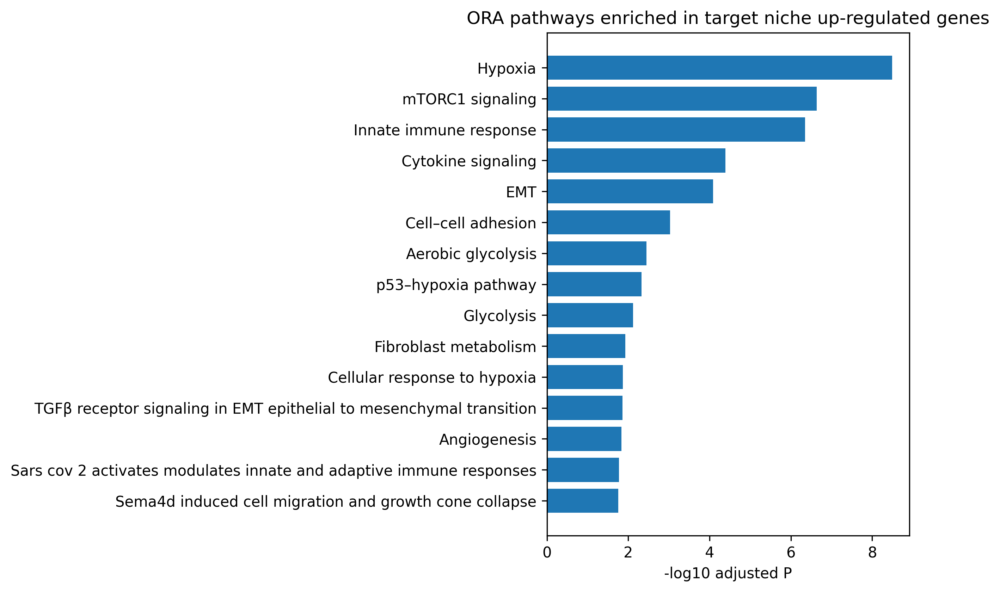

✅ ORA 通路图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8G_ORA_TargetNiche_Focus_Pathways_clean_labels.png


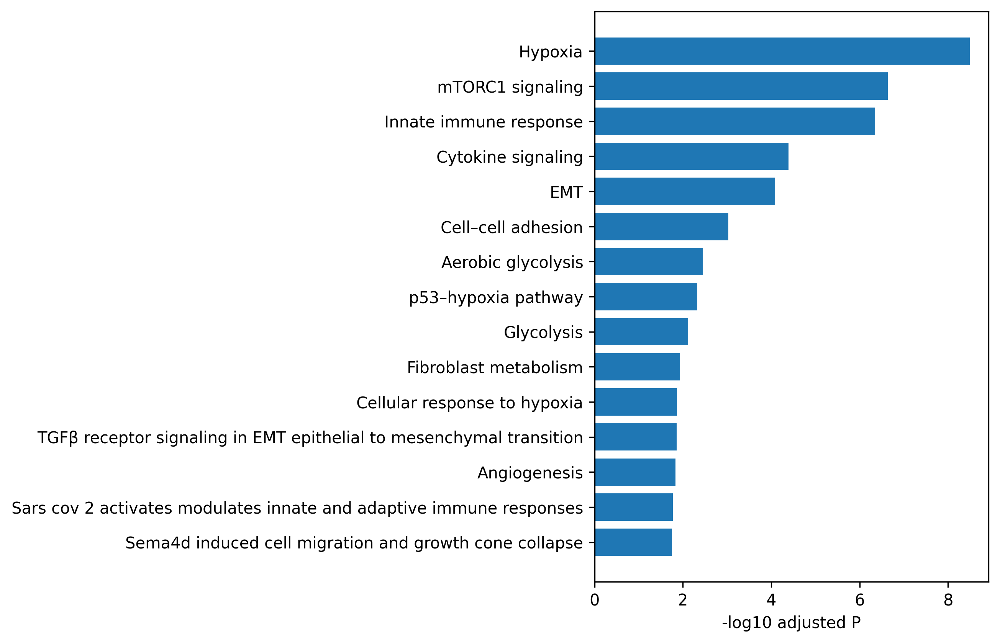

✅ 无标题 ORA 通路图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8G_ORA_TargetNiche_Focus_Pathways_clean_labels_no_title.png


In [15]:
# -----------------------------
# 4. ORA Top pathway 图
#    修改版：
#    1) 将数据库式 pathway 名称转换为论文常用简洁名称；
#    2) 删除重复通路，只保留 padj 更显著的一条；
#    3) 输出有标题版和无标题版两张图。
# -----------------------------

def simplify_pathway_name(term):
    """
    将 MSigDB / Reactome / Hallmark / WikiPathways / BioCarta 等数据库式通路名
    转换为高质量论文图中常用的简洁显示名称。
    """
    term = str(term)

    # 去掉 gmt 文件名前缀，例如：
    # c2.cp.v2026.1.Hs.symbols::REACTOME_INNATE_IMMUNE_SYSTEM
    if "::" in term:
        term = term.split("::")[-1]

    # 手动映射：优先用于 Result 8 中出现的核心通路
    manual_map = {
        "HALLMARK_HYPOXIA": "Hypoxia",
        "HALLMARK_MTORC1_SIGNALING": "mTORC1 signaling",
        "REACTOME_INNATE_IMMUNE_SYSTEM": "Innate immune response",
        "REACTOME_CYTOKINE_SIGNALING_IN_IMMUNE_SYSTEM": "Cytokine signaling",
        "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION": "EMT",
        "REACTOME_REGULATION_OF_HOMOTYPIC_CELL_CELL_ADHESION": "Cell–cell adhesion",
        "WP_AEROBIC_GLYCOLYSIS_AUGMENTED": "Aerobic glycolysis",
        "BIOCARTA_P53HYPOXIA_PATHWAY": "p53–hypoxia pathway",
        "HALLMARK_GLYCOLYSIS": "Glycolysis",
        "WP_METABOLIC_PATHWAYS_OF_FIBROBLASTS": "Fibroblast metabolism",
        "REACTOME_CELLULAR_RESPONSE_TO_HYPOXIA": "Cellular response to hypoxia",
    }

    if term in manual_map:
        return manual_map[term]

    # 通用清洗规则：去掉数据库来源前缀
    clean = term
    for prefix in [
        "HALLMARK_",
        "REACTOME_",
        "WP_",
        "BIOCARTA_",
        "KEGG_",
        "GOBP_",
        "GO_",
    ]:
        if clean.startswith(prefix):
            clean = clean.replace(prefix, "", 1)

    # 转换为自然语言格式
    clean = clean.replace("_", " ")
    clean = clean.lower()

    # 常见生物学缩写规范化
    replacements = {
        "mtorc1": "mTORC1",
        "pi3k": "PI3K",
        "akt": "AKT",
        "mapk": "MAPK",
        "tgfb": "TGFβ",
        "tgf beta": "TGFβ",
        "nfkb": "NF-κB",
        "p53": "p53",
        "dna": "DNA",
        "rna": "RNA",
        "ecm": "ECM",
        "emt": "EMT",
        "tca": "TCA",
        "ros": "ROS",
    }

    for old, new in replacements.items():
        clean = clean.replace(old, new)

    # 首字母大写，但保留特殊缩写
    if len(clean) > 0:
        clean = clean[0].upper() + clean[1:]

    return clean


plot_ora = ora_focus_df.copy()

# 如果机制相关通路太少，则退回使用全部 ORA 结果
if len(plot_ora) < 5:
    plot_ora = ora_df.copy()

if len(plot_ora) > 0:
    plot_ora = plot_ora.copy()

    # 生成论文风格简洁名称
    plot_ora["pathway_label"] = plot_ora["term"].apply(simplify_pathway_name)

    # 删除重复通路名称：
    # 例如 REACTOME_INNATE_IMMUNE_SYSTEM 和
    # c2.cp.v2026.1.Hs.symbols::REACTOME_INNATE_IMMUNE_SYSTEM
    # 会被统一成 Innate immune response，只保留 padj 最显著的一条
    plot_ora = (
        plot_ora
        .sort_values(["pathway_label", "padj", "pvalue", "overlap_count"],
                     ascending=[True, True, True, False])
        .drop_duplicates(subset=["pathway_label"], keep="first")
        .copy()
    )

    # 选择 Top 15
    plot_ora = (
        plot_ora
        .sort_values("padj", ascending=True)
        .head(15)
        .copy()
    )

    # 保存一份用于论文作图的清洗后通路表
    plot_ora_clean_csv = os.path.join(
        SAVE_DIR,
        "ORA_TargetNiche_Focus_Pathways_clean_labels_for_figure.csv"
    )
    plot_ora.to_csv(plot_ora_clean_csv, index=False, encoding="utf-8-sig")
    print("✅ 清洗后的 ORA 作图表已保存：", plot_ora_clean_csv)

    # 反转顺序，使最显著的通路显示在最上方
    plot_ora = plot_ora.iloc[::-1]

    # -----------------------------
    # 4.1 有标题版本
    # -----------------------------
    fig, ax = plt.subplots(
        figsize=(8.8, max(3.8, 0.38 * len(plot_ora))),
        dpi=300
    )

    ax.barh(
        plot_ora["pathway_label"],
        plot_ora["neglog10_padj"],
        height=0.78
    )

    # 手动调整边距：增大中间蓝色柱子所在的作图区域宽度
    plt.subplots_adjust(
        left=0.48,
        right=0.97,
        top=0.92,
        bottom=0.12
    )

    ax.set_xlabel("-log10 adjusted P")
    ax.set_ylabel("")
    ax.set_title("ORA pathways enriched in target niche up-regulated genes")

    ax.tick_params(axis="both", labelsize=10)
    plt.tight_layout()

    ora_fig = os.path.join(
        SAVE_DIR,
        "Fig8G_ORA_TargetNiche_Focus_Pathways_clean_labels.png"
    )
    plt.savefig(ora_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print("✅ ORA 通路图已保存：", ora_fig)

    # -----------------------------
    # 4.2 无标题版本
    # -----------------------------
    fig, ax = plt.subplots(
        figsize=(8.8, max(3.8, 0.38 * len(plot_ora))),
        dpi=300
    )

    ax.barh(
        plot_ora["pathway_label"],
        plot_ora["neglog10_padj"],
        height=0.78
    )

    # 手动调整边距：增大中间蓝色柱子所在的作图区域宽度
    plt.subplots_adjust(
        left=0.48,
        right=0.97,
        top=0.92,
        bottom=0.12
    )

    ax.set_xlabel("-log10 adjusted P")
    ax.set_ylabel("")
    ax.set_title("")

    ax.tick_params(axis="both", labelsize=10)
    plt.tight_layout()

    ora_fig_no_title = os.path.join(
        SAVE_DIR,
        "Fig8G_ORA_TargetNiche_Focus_Pathways_clean_labels_no_title.png"
    )
    plt.savefig(ora_fig_no_title, dpi=300, bbox_inches="tight")
    plt.show()
    print("✅ 无标题 ORA 通路图已保存：", ora_fig_no_title)

else:
    print("⚠️ ORA 结果为空，未绘制通路图。")

## Permutation 对照分析

这里做两个随机对照：

1. **病理 Tumor 区域 overlap permutation**：固定目标生态位 spot 数，随机抽取同样数量的 spots，计算落在病理 Tumor 区域的数量，比较真实值是否显著偏高。
2. **空间聚集 permutation**：固定目标生态位 spot 数，随机打乱 target 标签，计算 target spots 的 target-neighbor fraction，比较真实三轴生态位是否更空间聚集。

✅ Permutation 明细已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_Permutation_Details.csv
✅ Permutation 汇总已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_Permutation_Summary.csv


,test,real_value,random_mean,random_sd,empirical_pvalue_greater_equal,n_perm
0,Tumor_overlap_permutation,67.000000,33.682000,3.756711,0.001996,500
1,Target_neighbor_fraction_permutation,0.811567,0.106317,0.016898,0.001996,500


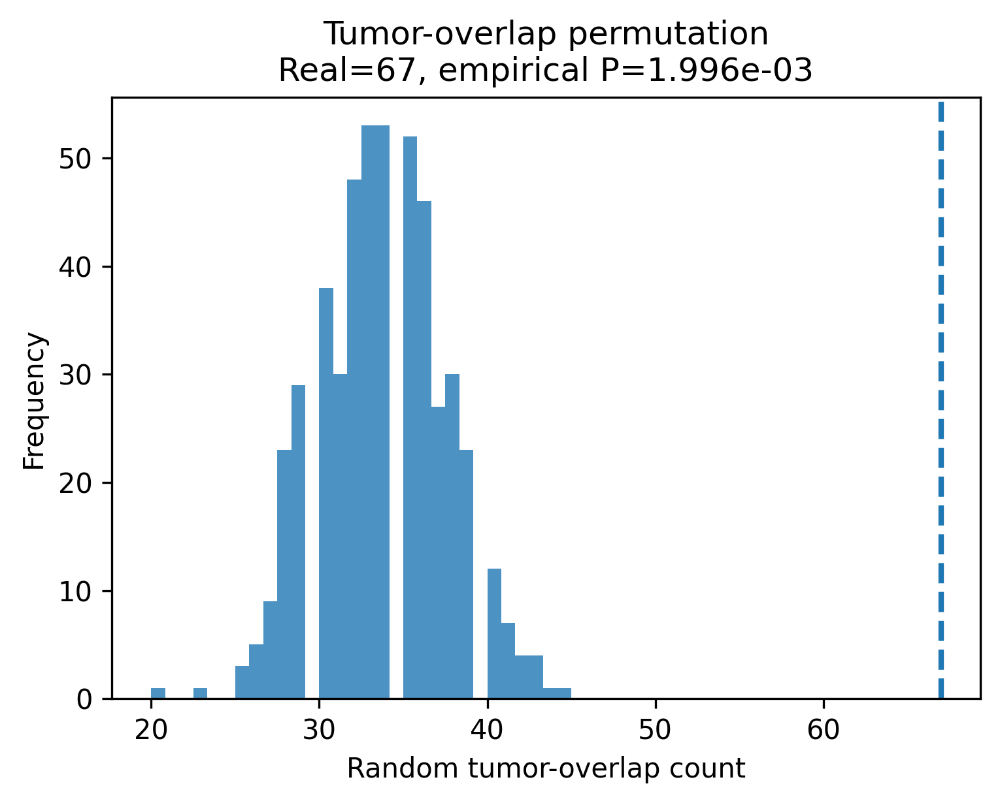

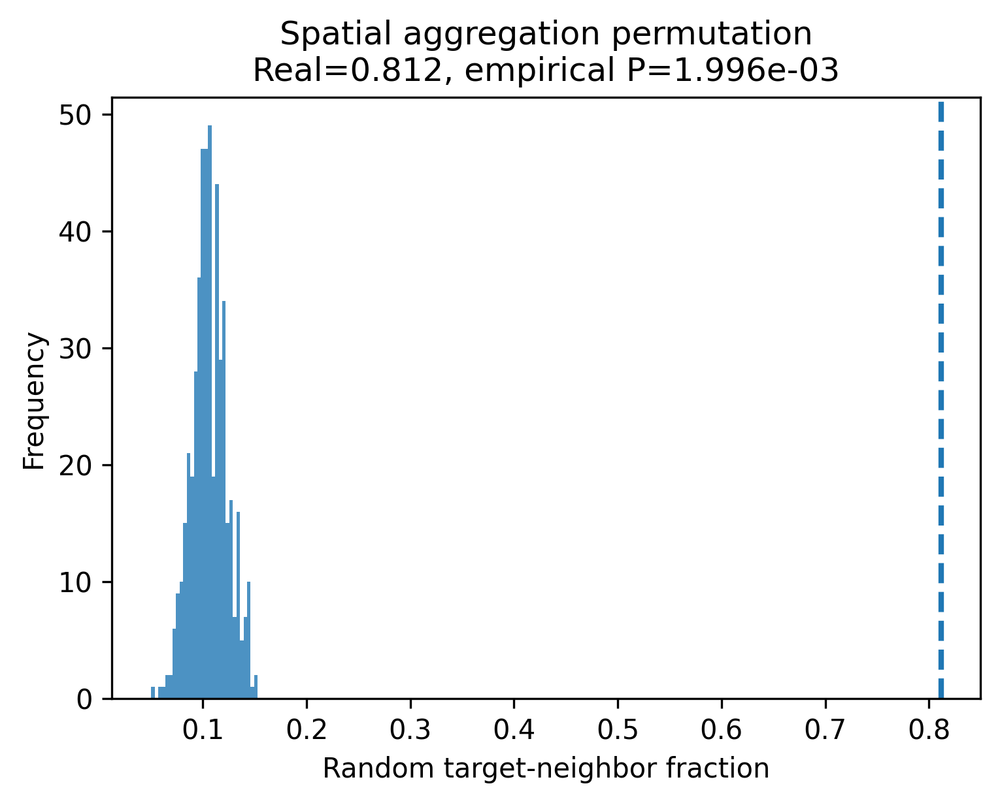

✅ Permutation 图已保存：
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8H_Permutation_TumorOverlap.png
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Fig8I_Permutation_TargetNeighborFraction.png


In [16]:
# =========================================================
# Cell 12: Permutation 对照：病理 Tumor overlap + 空间聚集
# =========================================================
rng = np.random.default_rng(RANDOM_SEED)

target_mask = adata.obs["Is_Target_Niche"].astype(bool).values
n_target = int(target_mask.sum())
pathology_tumor_mask = (adata.obs["Pathology_Binary_ARI"].astype(str).values == "Pathology_Tumor")
valid_pathology = adata.obs["Pathology_Binary_ARI"].astype(str).isin(["Pathology_Tumor", "Pathology_Non_Tumor"]).values

# -----------------------------
# 1. Tumor overlap permutation
# -----------------------------
real_tumor_overlap = int((target_mask & pathology_tumor_mask).sum())
valid_indices = np.where(valid_pathology)[0]
valid_target_count = int((target_mask & valid_pathology).sum())

perm_overlap = []
for i in range(N_PERM):
    perm_target_indices = rng.choice(valid_indices, size=valid_target_count, replace=False)
    perm_overlap.append(int(pathology_tumor_mask[perm_target_indices].sum()))
perm_overlap = np.asarray(perm_overlap)

overlap_perm_p = (np.sum(perm_overlap >= real_tumor_overlap) + 1) / (N_PERM + 1)

# -----------------------------
# 2. 空间聚集 permutation：target-neighbor fraction
# -----------------------------
coords = np.asarray(adata.obsm["spatial"])
nbrs = NearestNeighbors(n_neighbors=min(KNN_K + 1, adata.n_obs), metric="euclidean")
nbrs.fit(coords)
_, nn_idx = nbrs.kneighbors(coords)
nn_idx = nn_idx[:, 1:]

def compute_target_neighbor_fraction(mask):
    mask = np.asarray(mask, dtype=bool)
    if mask.sum() == 0:
        return np.nan
    target_rows = np.where(mask)[0]
    neigh = nn_idx[target_rows]
    return float(mask[neigh].mean())

real_neighbor_fraction = compute_target_neighbor_fraction(target_mask)
perm_neighbor_fraction = []
all_indices = np.arange(adata.n_obs)
for i in range(N_PERM):
    perm_mask = np.zeros(adata.n_obs, dtype=bool)
    perm_idx = rng.choice(all_indices, size=n_target, replace=False)
    perm_mask[perm_idx] = True
    perm_neighbor_fraction.append(compute_target_neighbor_fraction(perm_mask))
perm_neighbor_fraction = np.asarray(perm_neighbor_fraction)
neighbor_perm_p = (np.sum(perm_neighbor_fraction >= real_neighbor_fraction) + 1) / (N_PERM + 1)

# -----------------------------
# 保存 permutation 结果
# -----------------------------
perm_df = pd.DataFrame({
    "perm_id": np.arange(N_PERM),
    "random_tumor_overlap_count": perm_overlap,
    "random_target_neighbor_fraction": perm_neighbor_fraction,
})
perm_csv = os.path.join(SAVE_DIR, "Result8_Permutation_Details.csv")
perm_df.to_csv(perm_csv, index=False, encoding="utf-8-sig")

perm_summary = pd.DataFrame([
    {
        "test": "Tumor_overlap_permutation",
        "real_value": real_tumor_overlap,
        "random_mean": float(np.mean(perm_overlap)),
        "random_sd": float(np.std(perm_overlap)),
        "empirical_pvalue_greater_equal": overlap_perm_p,
        "n_perm": N_PERM,
    },
    {
        "test": "Target_neighbor_fraction_permutation",
        "real_value": real_neighbor_fraction,
        "random_mean": float(np.mean(perm_neighbor_fraction)),
        "random_sd": float(np.std(perm_neighbor_fraction)),
        "empirical_pvalue_greater_equal": neighbor_perm_p,
        "n_perm": N_PERM,
    },
])
perm_summary_csv = os.path.join(SAVE_DIR, "Result8_Permutation_Summary.csv")
perm_summary.to_csv(perm_summary_csv, index=False, encoding="utf-8-sig")

print("✅ Permutation 明细已保存：", perm_csv)
print("✅ Permutation 汇总已保存：", perm_summary_csv)
display(perm_summary)

# 绘图：两个独立图，避免子图太拥挤
fig, ax = plt.subplots(figsize=(5.2, 4.2), dpi=300)
ax.hist(perm_overlap, bins=30, alpha=0.8)
ax.axvline(real_tumor_overlap, linestyle="--", linewidth=2)
ax.set_xlabel("Random tumor-overlap count")
ax.set_ylabel("Frequency")
ax.set_title(f"Tumor-overlap permutation\nReal={real_tumor_overlap}, empirical P={overlap_perm_p:.3e}")
plt.tight_layout()
overlap_perm_fig = os.path.join(SAVE_DIR, "Fig8H_Permutation_TumorOverlap.png")
plt.savefig(overlap_perm_fig, dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.2), dpi=300)
ax.hist(perm_neighbor_fraction, bins=30, alpha=0.8)
ax.axvline(real_neighbor_fraction, linestyle="--", linewidth=2)
ax.set_xlabel("Random target-neighbor fraction")
ax.set_ylabel("Frequency")
ax.set_title(f"Spatial aggregation permutation\nReal={real_neighbor_fraction:.3f}, empirical P={neighbor_perm_p:.3e}")
plt.tight_layout()
neighbor_perm_fig = os.path.join(SAVE_DIR, "Fig8I_Permutation_TargetNeighborFraction.png")
plt.savefig(neighbor_perm_fig, dpi=300, bbox_inches="tight")
plt.show()

print("✅ Permutation 图已保存：")
print(overlap_perm_fig)
print(neighbor_perm_fig)

## 自动生成 Result 8 汇总报告

该报告不会把结论写死成“预后相关”，因为目前没有临床分期/生存/转移信息。  
推荐表述为：

> 该三轴混合生态位具有明确的病理区域相关性和医学功能解释性，提示 TuMeNiche 能够识别具有临床/医学意义的复合代谢微环境状态。

In [17]:
# =========================================================
# Cell 13: 自动生成 Result 8 汇总表与 Markdown 报告
# =========================================================
# 读取前面已生成的关键结果对象，自动汇总
summary = {
    "sample": SAMPLE_NAME,
    "target_niche": TARGET_NICHE,
    "n_spots": int(adata.n_obs),
    "n_genes_raw_used_for_deg": int(adata.n_vars),
    "target_niche_spots": int(adata.obs["Is_Target_Niche"].sum()),
}

# overlap
try:
    for _, row in overlap_summary.iterrows():
        summary[row["metric"]] = row["value"]
except Exception:
    pass

# boundary
try:
    if len(boundary_stats_df) > 0:
        for c in boundary_stats_df.columns:
            if c != "comparison":
                summary[f"boundary_{c}"] = boundary_stats_df.iloc[0][c]
except Exception:
    pass

# axis scores
try:
    for _, row in score_stats_df.iterrows():
        axis = row["Axis"]
        summary[f"{axis}_target_mean"] = row["Target_Niche_mean"]
        summary[f"{axis}_other_tumor_mean"] = row["Other_Tumor_Regions_mean"]
        summary[f"{axis}_pvalue"] = row["MannWhitneyU_pvalue"]
except Exception:
    pass

# cell fraction top features
try:
    if len(cell_stats_df) > 0:
        top_increased_cells = cell_stats_df.sort_values("target_minus_other_mean", ascending=False).head(8)["cell_type"].tolist()
        summary["top_increased_cell_types_in_target"] = ";".join(top_increased_cells)
except Exception:
    pass

# DEG top genes
try:
    summary["n_up_genes"] = int(len(up_df))
    summary["n_down_genes"] = int(len(down_df))
    summary["top_up_genes"] = ";".join(up_df.sort_values("ranking_score", ascending=False).head(20)["gene"].astype(str).tolist())
except Exception:
    pass

# ORA top pathways
try:
    if len(ora_focus_df) > 0:
        summary["top_focus_ora_pathways"] = ";".join(ora_focus_df.head(10)["term"].astype(str).tolist())
    elif len(ora_df) > 0:
        summary["top_ora_pathways"] = ";".join(ora_df.head(10)["term"].astype(str).tolist())
except Exception:
    pass

# permutation
try:
    for _, row in perm_summary.iterrows():
        test = row["test"]
        summary[f"{test}_real_value"] = row["real_value"]
        summary[f"{test}_random_mean"] = row["random_mean"]
        summary[f"{test}_empirical_pvalue"] = row["empirical_pvalue_greater_equal"]
except Exception:
    pass

summary_df = pd.DataFrame([summary])
summary_csv = os.path.join(SAVE_DIR, "Result8_Final_Summary.csv")
summary_df.to_csv(summary_csv, index=False, encoding="utf-8-sig")
print("✅ Result 8 汇总表已保存：", summary_csv)
display(summary_df.T)

# Markdown 报告
report_lines = []
report_lines.append(f"# Result 8 Summary: {SAMPLE_NAME} {TARGET_NICHE}")
report_lines.append("")
report_lines.append("## 1. Analysis design")
report_lines.append(f"This analysis evaluates whether the TuMeNiche-defined `{TARGET_NICHE}` niche in the LC5 lung cancer sample is associated with pathological tumor architecture and medically interpretable tumor microenvironment features.")
report_lines.append("")
report_lines.append("## 2. Key quantitative results")
report_lines.append(f"- Total spots analyzed: {summary.get('n_spots', 'NA')}")
report_lines.append(f"- Raw genes used for DEG/GSEA: {summary.get('n_genes_raw_used_for_deg', 'NA')}")
report_lines.append(f"- Target niche spots: {summary.get('target_niche_spots', 'NA')}")
report_lines.append(f"- Target spots in pathology tumor region: {summary.get('target_spots_in_Pathology_Tumor', 'NA')}")
report_lines.append(f"- Target tumor-overlap ratio: {summary.get('target_tumor_overlap_ratio', 'NA')}")
report_lines.append(f"- Fisher exact odds ratio: {summary.get('fisher_exact_odds_ratio', 'NA')}")
report_lines.append(f"- Fisher exact P value: {summary.get('fisher_exact_pvalue', 'NA')}")
report_lines.append("")
report_lines.append("## 3. Interpretation template")
report_lines.append("The identification of a `Multi_Axis_Lactate_Glutamine_LPA` niche suggests that TuMeNiche can capture a spatially restricted tumor microenvironment state with simultaneous lactate, glutamine, and LPA-axis activity. Because no patient-level survival, stage, recurrence, or metastasis information is available in this notebook, this result should be interpreted as medically interpretable pathological and functional relevance rather than direct prognostic association.")
report_lines.append("")
report_lines.append("## 4. Recommended manuscript wording")
report_lines.append("In the LC5 lung cancer sample, TuMeNiche identified a distinct Multi_Axis_Lactate_Glutamine_LPA niche. Spatial visualization showed that this niche was localized within the tissue architecture in relation to pathological tumor annotations. Further analyses evaluated tumor-region enrichment, tumor-boundary proximity, three-axis co-activation, SpaCET-derived cell composition, and functional enrichment relative to other tumor regions, supporting the biological interpretability of this multi-axis metabolic niche.")
report_lines.append("")
report_lines.append("## 5. Main output files")
report_lines.append("- Fig8A_Pathology_vs_Multi_Axis_Lactate_Glutamine_LPA_Highlight.png")
report_lines.append("- Result8_TargetNiche_Pathology_Overlap_Stats.csv")
report_lines.append("- Result8_ThreeAxis_Coactivation_Stats.csv")
report_lines.append("- Result8_CellFraction_Target_vs_OtherTumor_Stats.csv")
report_lines.append("- DEG_TargetNiche_vs_OtherTumorRegions_AllGenes.csv")
report_lines.append("- ORA_TargetNiche_UpGenes_vs_OtherTumor.csv")
report_lines.append("- Result8_Permutation_Summary.csv")

report_md = "\n".join(report_lines)
report_path = os.path.join(SAVE_DIR, "Result8_Summary_Report.md")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report_md)

print("✅ Markdown 报告已保存：", report_path)
print(report_md)

✅ Result 8 汇总表已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_Final_Summary.csv


,0
sample,LC5
target_niche,Multi_Axis_Lactate_Glutamine_LPA
n_spots,622
n_genes_raw_used_for_deg,17845
target_niche_spots,67
target_total_spots,67.0
target_spots_in_Pathology_Tumor,67.0
target_spots_in_Pathology_Non_Tumor,0.0
target_tumor_overlap_ratio,1.0
target_ratio_within_Pathology_Tumor,0.214744


✅ Markdown 报告已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC5_Multi_Axis_Lactate_Glutamine_LPA/Result8_Summary_Report.md
# Result 8 Summary: LC5 Multi_Axis_Lactate_Glutamine_LPA

## 1. Analysis design
This analysis evaluates whether the TuMeNiche-defined `Multi_Axis_Lactate_Glutamine_LPA` niche in the LC5 lung cancer sample is associated with pathological tumor architecture and medically interpretable tumor microenvironment features.

## 2. Key quantitative results
- Total spots analyzed: 622
- Raw genes used for DEG/GSEA: 17845
- Target niche spots: 67
- Target spots in pathology tumor region: 67.0
- Target tumor-overlap ratio: 1.0
- Fisher exact odds ratio: inf
- Fisher exact P value: 2.580561342773473e-22

## 3. Interpretation template
The identification of a `Multi_Axis_Lactate_Glutamine_LPA` niche suggests that TuMeNiche can capture a spatially restricted tumor microenvironment state with simultaneous lactate, glutamine, and LPA-axis activity. Because no patient-le

# 运行完成后的解读重点

运行完成后，优先查看以下文件：

1. `Fig8A_Pathology_vs_Multi_Axis_Lactate_Glutamine_LPA_Highlight.png`  
   - 这是主图：左病理区域，右三轴生态位高亮。

2. `Result8_TargetNiche_Pathology_Overlap_Stats.csv`  
   - 看目标生态位是否富集在病理 Tumor 区域。

3. `Result8_ThreeAxis_Coactivation_Stats.csv`  
   - 看 Lactate、Glutamine、LPA 三轴是否在目标生态位中共同增强。

4. `Result8_CellFraction_Target_vs_OtherTumor_Stats.csv`  
   - 看 Malignant、CAF、Macrophage、T cell 等细胞组成是否支持侵袭性/免疫抑制微环境解释。

5. `DEG_TargetNiche_vs_OtherTumorRegions_AllGenes.csv` 和 ORA/GSEA 结果  
   - 看是否富集 glycolysis、hypoxia、glutamine metabolism、ECM、EMT、angiogenesis、inflammatory response、TGF-beta、PI3K-AKT、MAPK 等通路。

6. `Result8_Permutation_Summary.csv`  
   - 看真实 overlap / 空间聚集是否显著高于随机。